# Construction du score PD du segment « Mono-détenus sans engagement »

Dans ce notebook, nous construisons le score de défaut du segment **SA** : les clients qui sont seuls titulaires de leur dossier et qui n'ont aucun crédit. Nous suivons l'ordre du cours, de la préparation des données jusqu'au calibrage des probabilités de défaut.

| Partie | Ce que nous faisons |
|---|---|
| 0 | Paramètres et chargement de la base |
| 1 | Population, cible, contrôles et découpage des échantillons |
| 2 | Préparation des données et création de nouvelles variables |
| 3 | Analyse exploratoire : liens entre variables et redondances |
| 4 | Discrétisation des variables (WoE, IV) |
| 5 | Régression logistique et modèle concurrent (XGBoost) |
| 6 | Grille de score (méthode du PDO) |
| 7 | Classes homogènes de risque (CHR) |
| 8 | Calibrage des probabilités de défaut |
| 9 et 10 | Suivi dans le temps et enjeux avancés |
| Annexe | Journal des décisions |

Quelques règles que nous suivons tout au long du notebook :

- **Un même client peut apparaître à plusieurs dates.** Nous découpons donc toujours les échantillons par client, et jamais par ligne.
- **L'échantillon de test est mis de côté dès le début.** Il ne sert qu'à mesurer la performance finale. Tous les choix sont faits sur le train.
- **Ce qui est appris sur le train est ensuite figé** : seuils de découpage, coefficients, classes de risque, probabilités. Il est simplement appliqué au test.
- **Les fonctions longues sont rangées dans le dossier `utils/`.** Le notebook les appelle et explique les choix.

## 0. Paramètres et chargement

Nous regroupons ici tous les seuils utilisés dans le notebook. Ainsi, si nous voulons en changer un, il suffit de le modifier à un seul endroit.

| Paramètre | Valeur | Pourquoi |
|---|---|---|
| `TEST_SIZE` | 20 % des clients | environ 90 défauts dans le test, ce qui suffit pour mesurer le Gini |
| `SEUIL_MANQUANTS` | 90 % | au-delà, une variable n'est presque jamais renseignée |
| `SEUIL_CONCENTRATION` | 99 % | une variable dont une seule valeur couvre 99 % des lignes ne sert à rien |
| `SEUIL_CORR` | 0,80 | deux variables plus corrélées que cela disent la même chose |
| `SEUIL_CRAMER` | 0,70 | même idée, mais pour des variables découpées en classes |
| `PART_MIN`, `DEFAUTS_MIN` | 5 % et 20 défauts | taille minimale d'une classe pour que son taux de défaut soit fiable |
| `ECART_MIN` | 30 % | écart de risque minimal entre deux classes voisines, vérifié chaque mois (règle du cours) |
| `PSI_MAX` | 0,10 | stabilité de la répartition des classes d'un mois à l'autre |
| `IV_MIN`, `IV_SUSPECT` | 0,02 et 0,50 | seuils de Siddiqi : en dessous de 0,02 la variable est inutile, au-dessus de 0,50 il faut vérifier qu'il n'y a pas de fuite |
| `ALPHA` | 5 % | seuil de significativité des tests |
| `NB_VARIABLES_MAX` | 10 | nombre maximal de variables dans la grille de score |
| `STEPWISE_CV_FOLDS` | 5 | nombre de blocs de la validation croisée utilisée pour choisir les variables |
| `NB_INTERACTIONS`, `NB_VARIABLES_INTERACTION` | 6 et 5 | nombre de variables croisées créées, et nombre de variables parmi lesquelles on les forme |
| `PDO`, `SCORE_REF`, `ODDS_REF` | 20, 600 et 50 | échelle de la grille : 600 points correspondent à 50 bons clients pour 1 mauvais, et 20 points de plus doublent ce rapport |
| `PD_PLANCHER` | 0,05 % | probabilité de défaut minimale imposée par la réglementation (CRR3) |
| `NIVEAU_MOC_C` | 90 % | niveau de confiance de la marge de prudence liée à l'erreur d'estimation |

In [121]:
# Librairies
import importlib
import os
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold, train_test_split
from xgboost import XGBClassifier

# Nos fonctions, rangées dans le dossier utils/
from utils import binning as bn
from utils import echelle_maitre as em
from utils import exploration as ex
from utils import feature_engineering as fe

# Recharge les modules si nous les avons modifiés, sans redémarrer le noyau
importlib.reload(bn)
importlib.reload(em)
importlib.reload(ex)
importlib.reload(fe)

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)

polars.config.Config

In [122]:
# Chemin de la base et dossier où nous enregistrons les résultats
CACHE = Path(os.environ.get("SCORING_BASE",
                            "data/segments/mono_sans_engagement/base_mono_sans_engagement.parquet"))
SORTIES = Path(os.environ.get("SCORING_SORTIES", "outputs/scorecard/SA_mono_sans_engagement"))

# Colonnes principales
ID_COL = "gdt"            # identifiant du client
DATE_COL = "datdelhis"    # mois d'observation, au format AAAAMM
DATE_OBS = "date_obs"     # le même mois, converti en vraie date pour calculer des durées
TARGET = "ddefaut_ndb"    # cible : défaut dans les 12 mois

# Découpage des échantillons
SEED = 42
TEST_SIZE = 0.20

# Partie 2 : préparation
SEUIL_MANQUANTS = 0.90
SEUIL_CONCENTRATION = 0.99

# Partie 3 : analyse exploratoire
SEUIL_CORR = 0.80
SEUIL_CRAMER = 0.70

# Partie 4 : discrétisation
PART_MIN = 0.05
DEFAUTS_MIN = 20
ECART_MIN = 0.30
PSI_MAX = 0.10
IV_MIN = 0.02
IV_SUSPECT = 0.50

# Partie 5 : modèle
ALPHA = 0.05
NB_VARIABLES_MAX = 10
GAIN_GINI_MIN = 0.0
STEPWISE_CV_FOLDS = 5

# Variables croisées (partie 2.4)
NB_INTERACTIONS = 6
NB_VARIABLES_INTERACTION = 5
PROFONDEUR_INTERACTION = 2

# Partie 6 : grille de score
PDO = 20
SCORE_REF = 600
ODDS_REF = 50

# Partie 8 : calibrage
PD_PLANCHER = 0.0005
NIVEAU_MOC_C = 0.90
MOC_A = 0.0   # marge pour les défauts de données : à fixer à dire d'expert
MOC_B = 0.0   # marge pour les choix de méthode : à fixer à dire d'expert

# Colonnes qui ne doivent jamais servir de variables explicatives
COLONNES_TECHNIQUES = {ID_COL, DATE_COL, DATE_OBS, TARGET}
COLONNES_ECHANTILLONNAGE = {"SamplingWeight", "SelectionProb"}

# Codes numériques qui sont en réalité des catégories (CSP, axe Banque Privée)
COLONNES_CATEGORIELLES_NUMERIQUES = {"CODACVPRO_modif", "code_axe_unite"}

### Chargement de la base

Avant de commencer, nous faisons trois petites corrections :

1. les valeurs `NaN` et les textes « NaN » ou vides sont transformés en vraies valeurs manquantes, sinon elles ne seraient pas comptées comme manquantes ;
2. la CSP (`CODACVPRO_modif`) et l'axe client (`code_axe_unite`) sont des codes : nous les transformons en texte pour les traiter comme des catégories ;
3. nous ajoutons une colonne `date_obs`, qui est le mois d'observation sous forme de date. Elle nous servira à calculer des durées, par exemple le nombre de mois depuis le dernier défaut.

In [123]:
# Lecture de la base
base = pl.read_parquet(CACHE)

In [124]:
# 1. Les NaN deviennent des valeurs manquantes
base = ex.nan_to_null(base)

colonnes_texte = [c for c, t in base.schema.items() if t == pl.String]
for c in colonnes_texte:
    base = base.with_columns(
        pl.when(pl.col(c).is_in(["NaN", "nan", ""])).then(None).otherwise(pl.col(c)).alias(c)
    )

In [125]:
# 2. Les codes deviennent des catégories (texte)
for c in COLONNES_CATEGORIELLES_NUMERIQUES:
    if c in base.columns:
        base = base.with_columns(pl.col(c).cast(pl.Int64, strict=False).cast(pl.String))

# 3. Le mois d'observation sous forme de date
base = base.with_columns(fe.en_date(base, DATE_COL).alias(DATE_OBS))

In [126]:
# Vérification
print(f"Dimensions de la base : {base.shape}")
print(f"Mois d'observation : {sorted(base[DATE_COL].unique().to_list())}")

Dimensions de la base : (78118, 174)
Mois d'observation : [datetime.date(2021, 1, 1), datetime.date(2021, 2, 1), datetime.date(2021, 3, 1), datetime.date(2021, 4, 1)]


## 1. Population, cible et découpage des échantillons

### 1.2 Population, cible et fenêtre d'observation

- **Population** : les clients seuls titulaires de leur dossier et sans crédit. Ce segment a été défini dans le notebook de segmentation.
- **Cible** : `ddefaut_ndb` vaut 1 si le client fait défaut **dans les 12 mois** qui suivent la date d'observation. Toutes les variables explicatives doivent donc être connues à cette date.
- **Période** : nous disposons de quatre mois d'observation. C'est court, et nous en tiendrons compte au moment du calibrage (partie 8).

In [127]:
# Nombre de dates et de lignes pour chaque client
dates_par_client = base.group_by(ID_COL).agg(
    pl.col(DATE_COL).n_unique().alias("nb_dates"),
    pl.len().alias("nb_lignes"),
)

In [128]:
print(f"Clients distincts : {dates_par_client.height} | lignes : {base.height}")
print(dates_par_client.group_by("nb_dates").agg(pl.len().alias("nb_clients")).sort("nb_dates"))

Clients distincts : 76452 | lignes : 78118
shape: (3, 2)
┌──────────┬────────────┐
│ nb_dates ┆ nb_clients │
│ ---      ┆ ---        │
│ u32      ┆ u32        │
╞══════════╪════════════╡
│ 1        ┆ 74810      │
│ 2        ┆ 1618       │
│ 3        ┆ 24         │
└──────────┴────────────┘


**Interprétation.** La base contient **78 118 lignes pour 76 452 clients**, répartis sur **4 mois d'observation**. Une ligne correspond donc à un client observé à une date, et non à un contrat.

| Nombre de dates par client | Clients | Part |
|---|---|---|
| 1 | 74 810 | 97,85 % |
| 2 | 1 618 | 2,12 % |
| 3 | 24 | 0,03 % |

Presque tous les clients n'apparaissent qu'une fois. Les 2 % restants apparaissent plusieurs fois, et nous devons faire attention à eux : si un même client se retrouvait à la fois dans le train et dans le test, le modèle serait évalué sur des clients qu'il a déjà vus. C'est pour cela que nous découpons les échantillons par client.

In [129]:
# Le couple (client, date) doit être unique
nb_doublons_cle = base.height - base.select([ID_COL, DATE_COL]).unique().height
print(f"Doublons sur le couple ({ID_COL}, {DATE_COL}) : {nb_doublons_cle}")

Doublons sur le couple (gdt, datdelhis) : 0


**Interprétation.** Il n'y a aucun doublon : un client a au plus une ligne par mois. Le couple (client, date) identifie donc bien chaque observation.

In [130]:
# Taux de défaut pour chaque mois d'observation
defaut_par_date = (
    base.group_by(DATE_COL)
    .agg(
        nb_lignes=pl.len(),
        nb_defauts=pl.col(TARGET).sum(),
        taux_defaut=pl.col(TARGET).mean(),
    )
    .sort(DATE_COL)
)
print(defaut_par_date)

shape: (4, 4)
┌────────────┬───────────┬────────────┬─────────────┐
│ datdelhis  ┆ nb_lignes ┆ nb_defauts ┆ taux_defaut │
│ ---        ┆ ---       ┆ ---        ┆ ---         │
│ date       ┆ u32       ┆ f64        ┆ f64         │
╞════════════╪═══════════╪════════════╪═════════════╡
│ 2021-01-01 ┆ 19543     ┆ 108.0      ┆ 0.005526    │
│ 2021-02-01 ┆ 19461     ┆ 94.0       ┆ 0.00483     │
│ 2021-03-01 ┆ 19147     ┆ 84.0       ┆ 0.004387    │
│ 2021-04-01 ┆ 19967     ┆ 163.0      ┆ 0.008163    │
└────────────┴───────────┴────────────┴─────────────┘


En janvier, on avait 0.5% de defaut, 0.4% de defaut en fevrier, 0.4% aussi en Mars et enfin on a 0.8% en Avril.

In [131]:
# Test du chi² : le taux de défaut est-il le même tous les mois ?
table_dates = defaut_par_date.select(
    (pl.col("nb_lignes") - pl.col("nb_defauts")).alias("sains"),
    pl.col("nb_defauts"),
).to_numpy()

chi2_dates, p_dates, ddl_dates, _ = stats.chi2_contingency(table_dates)
print(f"chi² = {chi2_dates:.2f} | ddl = {ddl_dates} | p-value = {p_dates:.4f}")

chi² = 29.63 | ddl = 3 | p-value = 0.0000


**Lecture.** Les volumes sont stables (environ 19 000 à 20 000 observations par mois). La fréquence de défaut baisse légèrement de janvier à mars (de **0,55 % à 0,44 %**), puis remonte à **0,82 % en avril**. 

**Conséquences.**
- Les taux mensuels sont des fréquences observées ponctuelles (**PIT**). Ils ne peuvent pas servir directement de PD : le calibrage s'appuie sur un **LRA** (§8.4).
- La stabilité des découpages et des CHR est contrôlée **mois par mois** (§4.6, §7.2).
- La hausse d'avril peut avoir plusieurs causes : effet conjoncturel, effet de fenêtre ou changement de définition. Elle est signalée comme point d'attention dans le journal des décisions.

In [132]:
# Nombre de défauts par client
defauts_par_client = base.group_by(ID_COL).agg(pl.col(TARGET).sum().alias("nb_defauts_client"))

print(
    defauts_par_client.filter(pl.col("nb_defauts_client") > 0)
    .group_by("nb_defauts_client")
    .agg(pl.len().alias("nb_clients"))
    .sort("nb_defauts_client")
)

shape: (2, 2)
┌───────────────────┬────────────┐
│ nb_defauts_client ┆ nb_clients │
│ ---               ┆ ---        │
│ f64               ┆ u32        │
╞═══════════════════╪════════════╡
│ 1.0               ┆ 431        │
│ 2.0               ┆ 9          │
└───────────────────┴────────────┘


In [133]:
# Pour les clients qui ont deux lignes en défaut : dans quel ordre les défauts arrivent-ils ?
clients_multi_defaut = defauts_par_client.filter(pl.col("nb_defauts_client") >= 2)[ID_COL]

rang = pl.int_range(pl.len())                     # position de la ligne dans l'historique du client
rang_defaut = rang.filter(pl.col(TARGET) == 1)    # positions des lignes en défaut

chronologie = (
    base.filter(pl.col(ID_COL).is_in(clients_multi_defaut.implode()))
    .sort(ID_COL, DATE_OBS)
    .group_by(ID_COL, maintain_order=True)
    .agg(
        # suite des cibles, par exemple "1-1" ou "1-0-1"
        sequence=pl.col(TARGET).cast(pl.Int64).cast(pl.String).str.join("-"),
        # nombre de mois entre le premier et le dernier défaut
        mois_entre_defauts=(
            pl.col(DATE_OBS).filter(pl.col(TARGET) == 1).max()
            - pl.col(DATE_OBS).filter(pl.col(TARGET) == 1).min()
        ).dt.total_days() / 30.4375,
        # y a-t-il une ligne saine entre les deux défauts ?
        sain_intercale=((rang > rang_defaut.min()) & (rang < rang_defaut.max()) & (pl.col(TARGET) == 0)).any(),
    )
)

print(
    chronologie.group_by("sequence", "sain_intercale")
    .agg(nb_clients=pl.len(), mois_moyen=pl.col("mois_entre_defauts").mean().round(1))
    .sort("nb_clients", descending=True)
)

shape: (1, 4)
┌──────────┬────────────────┬────────────┬────────────┐
│ sequence ┆ sain_intercale ┆ nb_clients ┆ mois_moyen │
│ ---      ┆ ---            ┆ ---        ┆ ---        │
│ str      ┆ bool           ┆ u32        ┆ f64        │
╞══════════╪════════════════╪════════════╪════════════╡
│ 1-1      ┆ false          ┆ 9          ┆ 1.3        │
└──────────┴────────────────┴────────────┴────────────┘


**Lecture.** **440 clients** ont fait défaut au moins une fois : 431 une fois, 9 deux fois. Cela représente **440 lignes en défaut**, soit environ **0,57 %** des observations.

**Interprétation des 9 doubles défauts.** La cible regarde vers l'avenir (défaut dans les 12 mois). Deux observations rapprochées d'un même client portent donc en général **le même événement de défaut**, compté deux fois. Un retour au défaut après guérison ne serait vraisemblable qu'avec une séquence « 1-0-1 ».

**Décision.** Les lignes sont conservées : chaque date est une observation légitime d'un client sain à cette date. La non-indépendance est traitée par le découpage par client et l'inférence cluster-robust. L'impact est négligeable (9 lignes sur 449).

**Conséquence pour la suite.** Avec un taux de défaut aussi faible, chaque classe doit contenir un minimum de défauts (`DEFAUTS_MIN = 20`) pour que son WoE soit stable.

### 1.3 Contrôles bloquants

Avant d'aller plus loin, nous vérifions que la base est utilisable. La fonction `valider_base` contrôle que :

- les colonnes identifiant, date et cible existent et ne contiennent pas de valeurs manquantes ;
- le couple (client, date) est unique ;
- la cible ne prend que les valeurs 0 et 1, et contient bien les deux ;
- il existe au moins une variable numérique utilisable.

Si l'un de ces contrôles échoue, le notebook s'arrête avec un message d'erreur. Nous préférons arrêter plutôt que de corriger la base sans le savoir.

In [134]:
def valider_base(df, id_col, date_col, target, exclues=frozenset()):
    # Les colonnes clés doivent exister et être complètes
    for col in (id_col, date_col, target):
        if col not in df.columns:
            raise ValueError(f"Colonne absente : {col!r}")
        if df[col].null_count() > 0:
            raise ValueError(f"Valeurs manquantes dans {col!r}")

    # Le couple (client, date) doit être unique
    doublons = df.height - df.select([id_col, date_col]).unique().height
    if doublons > 0:
        raise ValueError(f"{doublons} doublons sur le couple ({id_col}, {date_col})")

    # La cible doit valoir 0 ou 1, avec les deux valeurs présentes
    modalites = set(df[target].unique().to_list())
    if not modalites <= {0, 1} or len(modalites) < 2:
        raise ValueError(f"Cible invalide : {sorted(modalites, key=str)}")

    # Il faut au moins une variable numérique utilisable
    a_exclure = {id_col, date_col, target} | set(exclues)
    variables = [c for c, t in df.schema.items() if t.is_numeric() and c not in a_exclure]
    if not variables:
        raise ValueError("Aucune variable numérique utilisable")
    return variables

In [135]:
variables_num = valider_base(base, ID_COL, DATE_COL, TARGET,
                             exclues=COLONNES_TECHNIQUES | COLONNES_ECHANTILLONNAGE)
print(f"Tous les contrôles sont passés. Variables numériques brutes : {len(variables_num)}")

Tous les contrôles sont passés. Variables numériques brutes : 152


### 1.4 Segmentation

Le segment a été défini dans le notebook de segmentation : `nb_tiers = 1` et `has_engagement = 0`. Ces deux variables ont donc la même valeur pour tous nos clients, et nous les retirons des variables explicatives (partie 2.5).

### 1.5 Découpage des échantillons

Nous découpons la base en deux échantillons, **toujours par client** :

| Échantillon | Part | À quoi il sert |
|---|---|---|
| Train | 80 % des clients | construire les découpages, les variables croisées et estimer les modèles |
| Test | 20 % des clients | comparer les méthodes de découpage, arrêter XGBoost et mesurer la performance finale |

Le tirage est **stratifié** sur le fait que le client a fait défaut au moins une fois. Les deux échantillons gardent ainsi la même proportion de défauts. Il n'y a pas d'échantillon de validation séparé : la sélection des variables se fait par validation croisée sur le train (partie 5.1).


In [136]:
# Une ligne par client, avec un indicateur « a fait défaut au moins une fois »
clients = (
    base.group_by(ID_COL)
    .agg((pl.col(TARGET).max() > 0).cast(pl.Int8).alias("client_en_defaut"))
    .sort(ID_COL)
)

In [137]:
# Tirage des clients du test (20 %)
train_ids, test_ids = train_test_split(
    clients[ID_COL].to_list(),
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=clients["client_en_defaut"].to_list(),
)

In [139]:
def selon_ids(df, ids):
    # Garde uniquement les lignes des clients dont l'identifiant est dans la liste
    liste = pl.DataFrame({ID_COL: ids}, schema={ID_COL: df.schema[ID_COL]})
    return df.join(liste, on=ID_COL, how="semi")

In [141]:
train = selon_ids(base, train_ids)
test = selon_ids(base, test_ids)

In [142]:
# Contrôles : aucun client commun et aucune ligne perdue
clients_communs = set(train[ID_COL].to_list()) & set(test[ID_COL].to_list())
if clients_communs:
    raise RuntimeError("Des clients sont à la fois dans le train et dans le test.")
if train.height + test.height != base.height:
    raise RuntimeError("Des lignes ont été perdues pendant le découpage.")

In [143]:
for nom, df in (("Train", train), ("Test", test)):
    print(f"{nom:5s} | clients = {df[ID_COL].n_unique():>6} | lignes = {df.height:>6} "
          f"| défauts = {int(df[TARGET].sum()):>4} | taux = {df[TARGET].mean():.4%}")

Apprentissage | clients =  45870 | lignes =  46874 | défauts =  268 | taux = 0.5717%
Validation    | clients =  15291 | lignes =  15605 | défauts =   91 | taux = 0.5831%
Train         | clients =  61161 | lignes =  62479 | défauts =  359 | taux = 0.5746%
Test          | clients =  15291 | lignes =  15639 | défauts =   90 | taux = 0.5755%


**Lecture.** Le train (61 161 clients, 62 479 observations, 359 défauts, 0,575 %) et le test (15 291 clients, 15 639 observations, 90 défauts, 0,576 %) ont des taux de défaut quasiment identiques, ce qui montre que la stratification a fonctionné. Aucun client n'est commun aux deux échantillons. 

## 2. Préparation des données

### 2.1 Sources de données

Toutes les variables viennent des systèmes internes de la banque : fonctionnement du compte courant, épargne et avoirs, historique de défaut et d'arriérés, et informations sur le client (âge, ancienneté, CSP).

Nous n'utilisons ni données externes payantes ni données d'open banking. Le score reste ainsi simple à reproduire.

Les filtres de qualité de cette partie (manquants, variables constantes, valeurs extrêmes) n'utilisent pas la cible. Ils sont calculés sur le train.

### 2.2 Valeurs manquantes

Nous appliquons quatre règles :

1. une variable manquante dans **90 % des cas ou plus** est retirée, car elle est presque jamais renseignée ;
2. **exception** : pour `CAUSE_SAIN_M0` et `anciennete_jour_sain_M0`, une valeur manquante veut dire « le client n'a jamais été en défaut ». C'est une information utile, donc nous les gardons ;
3. pour les autres variables, **la valeur manquante est gardée comme une catégorie à part entière**. Nous ne la remplaçons pas : au moment de la discrétisation, elle formera sa propre classe ;
4. une variable dont une seule valeur couvre **99 % des lignes ou plus** est retirée, car elle ne distingue presque personne.

In [144]:
TYPES_QUALI = (pl.String, pl.Categorical, pl.Enum, pl.Boolean)
EXCLUES_TECHNIQUES = COLONNES_TECHNIQUES | COLONNES_ECHANTILLONNAGE
EXEMPTES_MANQUANTS = {"CAUSE_SAIN_M0", "anciennete_jour_sain_M0"}

In [145]:
def lister_variables(df, exclues):
    # Sépare les variables quantitatives et qualitatives, sans les colonnes exclues
    quanti = [c for c, t in df.schema.items() if t.is_numeric() and c not in exclues]
    quali = [c for c, t in df.schema.items() if isinstance(t, TYPES_QUALI) and c not in exclues]
    return quanti, quali

In [146]:
quanti_brutes, quali_brutes = lister_variables(train, EXCLUES_TECHNIQUES)
print(f"{len(quanti_brutes)} variables quantitatives et {len(quali_brutes)} variables qualitatives")

152 variables quantitatives et 13 variables qualitatives


In [147]:
# Taux de valeurs manquantes de chaque variable
toutes = quanti_brutes + quali_brutes
taux_manquants = pl.DataFrame({
    "variable": toutes,
    "type": ["quanti"] * len(quanti_brutes) + ["quali"] * len(quali_brutes),
    "taux_manquant": [train[c].null_count() / train.height for c in toutes],
}).sort("taux_manquant", descending=True)

display(taux_manquants.head(15))

variable,type,taux_manquant
str,str,f64
"""AGE_PM_EN_MOIS""","""quanti""",1.0
"""RATIO_LITIGES_vs_CA""","""quanti""",1.0
"""LISTE_CODACVPRO_modif""","""quali""",1.0
"""LISTE_CODNAF2""","""quali""",1.0
"""LISTE_CODETAJUR""","""quali""",1.0
"""MVTAFF_STABILITE_2T_vs_12M""","""quanti""",0.988732
"""CODITDBDF_PRO""","""quali""",0.98814
"""CRTOC_TOK_0010""","""quali""",0.98814
"""CODNAF2""","""quali""",0.987596


In [148]:
# Variables retirées pour excès de valeurs manquantes
trop_manquantes = taux_manquants.filter(
    (pl.col("taux_manquant") >= SEUIL_MANQUANTS)
    & ~pl.col("variable").is_in(list(EXEMPTES_MANQUANTS))
)
EXCLUES_MANQUANTS = set(trop_manquantes["variable"])
print(f"Retirées (manquantes dans {SEUIL_MANQUANTS:.0%} des cas ou plus) : {sorted(EXCLUES_MANQUANTS)}")

Retirées (manquantes dans 90% des cas ou plus) : ['AGE_PM_EN_MOIS', 'CODETAJUR', 'CODITDBDF_PRO', 'CODNAF2', 'CRTOC_TOK_0010', 'LISTE_CODACVPRO_modif', 'LISTE_CODETAJUR', 'LISTE_CODNAF2', 'MVTAFF_STABILITE_2T_vs_12M', 'RATIO_LITIGES_vs_CA']


In [149]:
# Variables quasi constantes
a_tester = [c for c in toutes if c not in EXCLUES_MANQUANTS]
rapport_constantes = ex.constant_report(train, a_tester, seuil=SEUIL_CONCENTRATION)

EXCLUES_CONSTANTES = set(rapport_constantes.filter(pl.col("quasi_constante"))["variable"])
print(f"Quasi constantes ({len(EXCLUES_CONSTANTES)}) : {sorted(EXCLUES_CONSTANTES)}")

Quasi constantes (76) : ['ARR_GDT', 'CODITDBDF_PAR', 'CRTAD_IND_0062', 'CRTOC_AG_LIGDEB_2T_IND_0015', 'CRTOC_AG_LIGDEB_IND_0015', 'CRTOC_AG_NBJDEB_2T_IND_0015', 'CRTOC_AG_NBJDEB_IND_0015', 'CRTOC_IND_0301', 'CRTOP_AG_IND_0038', 'Dfo_max_Mm1_Mm3', 'MNTAUTCRT_AG_EPTE_PAR', 'MNT_HA102', 'NBJ_ARR_SS', 'NB_CCT_PRO', 'RATIO3_PRO', 'TOTAL_EPS_PRO_IND_0208', 'TOTAL_LITIGES_PRO_IND_0209', 'TOTAL_TITRES_PRO_IND_0205', 'TX_UTIL_CCT_PRO', 'bilan', 'code_marche_v2', 'engagement', 'engagement_CB_diff', 'engagement_DAV', 'engagement_MLT', 'engagement_MLT__PGE', 'engagement_MLT__autre_OCM', 'engagement_MLT__autre_garantie', 'engagement_MLT__interfimo', 'engagement_MLT__sans_garantie', 'engagement_credit_LCP', 'engagement_credit_PGE', 'engagement_credit_autre', 'engagement_credit_bail', 'engagement_credit_flex', 'engagement_credit_garantie_emise', 'engagement_credit_neiertz', 'engagement_credit_perso', 'engagement_credit_revolving', 'engagement_credit_tresorerie', 'engagement_immo', 'engagement_immo__a

**Justification des variables écartées.** Lors de la première analyse, trois variables dépassaient 90 % de manquants : `AGE_PM_EN_MOIS`, `MVTAFF_STABILITE_2T_vs_12M` et `RATIO_LITIGES_vs_CA`. Ce sont des variables de **personne morale ou d'activité professionnelle** (âge de l'entreprise, mouvements d'affaires, chiffre d'affaires), structurellement absentes pour une clientèle de particuliers. Elles sont écartées parce qu'elles **ne s'appliquent pas** au segment, et non pour un motif RGPD : aucune n'est une donnée sensible.

**Choix du seuil de concentration (99 % plutôt que 90 %).** Avec un seuil à 90 %, plus de 100 variables étaient écartées, dont des indicateurs rares mais très discriminants : un historique de défaut ne concerne que 2 à 3 % des clients, alors que son taux de défaut est près de 8 fois supérieur. Le pouvoir discriminant de ces variables est jugé au binning (IV), qui gère les modalités rares (§4.5). Le filtre ne retire donc ici que les variables réellement constantes.

**Pourquoi un seuil de 99 % et non de 90 % pour les variables quasi constantes ?** Avec 90 %, nous retirions plus de 100 variables, dont certaines très utiles. Par exemple, un historique de défaut ne concerne que 2 à 3 % des clients, mais ces clients font beaucoup plus souvent défaut que les autres. Nous préférons laisser la discrétisation (partie 4) juger de l'utilité de ces variables.

**Pourquoi les variables trop manquantes sont-elles retirées ?** Les trois variables concernées au départ (`AGE_PM_EN_MOIS`, `MVTAFF_STABILITE_2T_vs_12M` et `RATIO_LITIGES_vs_CA`) décrivent des entreprises ou des professionnels : âge de l'entreprise, chiffre d'affaires, mouvements d'affaires. Elles sont vides pour des particuliers. Nous les retirons parce qu'elles ne concernent pas notre segment, et non pour une raison liée au RGPD.

### 2.3 Valeurs extrêmes

Nous repérons les valeurs extrêmes avec la règle de l'écart interquartile : une valeur est extrême si elle est en dessous de Q1 − 3 × IQR ou au-dessus de Q3 + 3 × IQR.

**Nous ne les corrigeons pas**, pour deux raisons :

- les variables seront découpées en classes (partie 4). Une valeur extrême tombe simplement dans la première ou la dernière classe, sans fausser le modèle ;
- pour des montants bancaires (encours, flux, soldes), une valeur très élevée est souvent réelle et apporte de l'information.

In [150]:
quanti_a_controler = [c for c in quanti_brutes if c not in EXCLUES_MANQUANTS | EXCLUES_CONSTANTES]
rapport_outliers = ex.outlier_report(train, quanti_a_controler, method="iqr", k=3)
display(rapport_outliers.sort("taux_outliers", descending=True, nulls_last=True).head(15))

variable,n_outliers,taux_outliers,borne_basse,borne_haute
str,i64,f64,f64,f64
"""CRTAV_IND_0165""",13684,0.219018,0.0,0.0
"""CRTAD_AG_NBJDE_BC""",12354,0.19773,0.0,0.0
"""SOLDE_PENTE_3T""",11593,0.18555,-116165.0,132331.5
"""SOLDE_PENTE_4T""",11243,0.179948,-99899.9,121767.0
"""SOLDE_PENTE_5T""",11074,0.177244,-87366.4,110499.8
"""CRTAD_AG_NBJDE_BB""",11054,0.176923,0.0,0.0
"""CRTAD_AG_NBJDE_BA""",9835,0.157413,-21.0,28.0
"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",4755,0.144209,-8.498511,11.544792
"""CRTAE_AG_SLDEPA""",7624,0.122025,-1.452e6,1.936e6


### 2.4 Création de nouvelles variables

Pour un client sans crédit, le risque se lit surtout dans quatre domaines : ses incidents passés, le fonctionnement de son compte courant, sa situation financière et sa relation avec la banque. Les variables brutes donnent souvent une photo à un instant donné. Nous créons des variables qui ajoutent une notion de **durée**, d'**intensité** ou de **répétition**. Toutes les fonctions sont dans `utils/feature_engineering.py`.

| Domaine | Variable créée | Comment elle est calculée | Pourquoi elle peut aider |
|---|---|---|---|
| Indicateurs | `TOP_LITIGE` | le client a au moins un litige | un litige en cours montre une difficulté |
| | `TOP_GARANTIE_IMMO` | le client a un crédit immobilier garanti | contrôle : elle devrait valoir 0 dans un segment sans crédit |
| Défaut passé | `TOP_HISTO_DEFAUT` | le client a déjà été en défaut | c'est le facteur de risque le plus fort vu en segmentation |
| | `RECENCE_DFO_MOIS` | nombre de mois depuis le dernier défaut | un défaut récent est plus inquiétant qu'un défaut ancien |
| | `DUREE_DFO_MOIS` | durée du dernier défaut, en mois | un défaut long montre une fragilité durable |
| | `RECENCE_SAIN_MOIS` | nombre de mois depuis le retour à une situation saine | un client qui vient d'en sortir reste fragile |
| Arriérés | `NB_FENETRES_DFO_48M`, `NB_FENETRES_ARR_48M` | nombre de périodes avec un défaut ou un arriéré sur 4 ans | les incidents qui se répètent |
| | `MAX_NBJ_ARR_12M` | plus grand nombre de jours d'arriéré sur 12 mois | la gravité des incidents récents |
| | `RECENCE_ARR_MOIS` | nombre de mois depuis le dernier arriéré | la proximité du dernier incident |
| Compte courant | `TOP_DEBIT_NON_AUTO` | le client a dépassé son découvert autorisé | signe de tension |
| | `PART_JOURS_DEBITEURS_15M` | part des jours à découvert sur 15 mois | un découvert permanent |
| | `LOG_NB_ECRITURES`, `TOP_COMPTE_INACTIF` | activité du compte | un compte peu ou pas utilisé |
| | `TOP_SOLDE_MIN_NEGATIF` | le solde minimal est négatif | le compte passe dans le rouge |
| Situation financière | `RATIO_DEBIT_CREDIT_12M` | sorties d'argent divisées par les entrées sur 12 mois | un client qui dépense plus qu'il ne gagne |
| | `LOG_FLUX_CREDITEURS_12M` | entrées d'argent sur 12 mois | une idée du revenu |
| | `LOG_AVOIRS`, `TOP_SANS_AVOIRS` | total de l'épargne et des placements | la capacité à faire face à un imprévu |
| | `MOIS_ENTREES_EN_AVOIRS` | épargne divisée par les entrées mensuelles | le nombre de mois de revenus mis de côté |
| Relation | `AGE_ENTREE_ANS` | âge au moment de l'entrée à la banque | distingue un jeune client d'un client arrivé tard |
| | `PART_VIE_CLIENT` | ancienneté divisée par le nombre d'années depuis 18 ans | la fidélité, indépendamment de l'âge |
| Information | `NB_MANQUANTS` | nombre d'informations clés manquantes | un dossier peu renseigné |
| Croisements | `INTER_1` à `INTER_6` | petits arbres de décision sur deux variables | voir plus bas |

Quelques précautions :

- ces calculs n'apprennent rien des données. Nous les appliquons donc de la même façon au train et au test ;
- une date d'historique postérieure à la date d'observation est ignorée, car elle reviendrait à utiliser une information du futur ;
- pour les variables de récence, une valeur manquante veut dire « jamais en défaut ». Elle forme sa propre classe.

In [151]:
# Combien de dates d'historique sont postérieures à la date d'observation ? (elles seront ignorées)
dates_futures = fe.controler_dates_futures(train, DATE_OBS, ["DATE_DERNIER_DFO", "DATE_SAIN", "DATE_PREMIER_ARR"])
print(dates_futures)

{'DATE_DERNIER_DFO': 0, 'DATE_SAIN': 608, 'DATE_PREMIER_ARR': 0}


In [152]:
COLS_THIN_FILE = ["AGE_PP_EN_MOIS", "ANCIENNETE_modif", "CODACVPRO_modif",
                  "ENCOURS_PAR", "CRTAD_IND_0042", "solde_DAV_moyen"]


def creer_variables(df):
    # Applique une à une les fonctions de création de variables
    df = fe.ajouter_tops_litige_garantie(df)
    df = fe.ajouter_historique_defaut(df, DATE_OBS)
    df = fe.ajouter_historique_arrieres(df)
    df = fe.ajouter_comportement_compte(df)
    df = fe.ajouter_flux_patrimoine(df)
    df = fe.ajouter_age_anciennete(df)
    df = fe.ajouter_nb_manquants(df, COLS_THIN_FILE)
    return df

In [153]:
colonnes_avant = set(train.columns)

train = creer_variables(train)
test = creer_variables(test)

NOUVELLES_FEATURES = [c for c in train.columns if c not in colonnes_avant]
print(f"{len(NOUVELLES_FEATURES)} variables créées : {NOUVELLES_FEATURES}")

23 variables créées : ['TOP_LITIGE', 'TOP_GARANTIE_IMMO', 'TOP_HISTO_DEFAUT', 'RECENCE_DFO_MOIS', 'DUREE_DFO_MOIS', 'RECENCE_SAIN_MOIS', 'NB_FENETRES_DFO_48M', 'NB_FENETRES_ARR_48M', 'MAX_NBJ_ARR_12M', 'RECENCE_ARR_MOIS', 'TOP_DEBIT_NON_AUTO', 'PART_JOURS_DEBITEURS_15M', 'LOG_NB_ECRITURES', 'TOP_COMPTE_INACTIF', 'TOP_SOLDE_MIN_NEGATIF', 'RATIO_DEBIT_CREDIT_12M', 'LOG_FLUX_CREDITEURS_12M', 'LOG_AVOIRS', 'TOP_SANS_AVOIRS', 'MOIS_ENTREES_EN_AVOIRS', 'AGE_ENTREE_ANS', 'PART_VIE_CLIENT', 'NB_MANQUANTS']


In [154]:
# Pouvoir discriminant de chaque variable créée (Gini calculé sur le train)
gini_nouvelles = fe.gini_univarie(train, NOUVELLES_FEATURES, TARGET)
display(gini_nouvelles)

variable,gini,taux_manquant,n_classes
str,f64,f64,i64
"""RECENCE_SAIN_MOIS""",0.46299,0.009984,10
"""PART_JOURS_DEBITEURS_15M""",0.456515,0.0,5
"""LOG_AVOIRS""",0.349805,0.0,8
"""NB_FENETRES_ARR_48M""",0.29759,0.0,9
"""RECENCE_ARR_MOIS""",0.295222,0.906174,9
"""PART_VIE_CLIENT""",0.264966,0.0,8
"""NB_FENETRES_DFO_48M""",0.228181,0.0,9
"""RECENCE_DFO_MOIS""",0.215393,0.967999,11
"""TOP_HISTO_DEFAUT""",0.211747,0.0,2


**Interprétation :** Plusieurs variables presente un gini élevé qui implique qu'elle contribue bien à l'explication de la cible seulement trois variables TOP_LITIGE, TOP_GARANTIE_IMMO et NB_MANQUANTS presentent un gini nul.

Pour calculer ce Gini, nous découpons chaque variable en dix classes de même taille, plus une classe pour les valeurs manquantes, et nous utilisons le taux de défaut de chaque classe comme score. C'est seulement une première indication : la vraie sélection se fait après la discrétisation (partie 4) puis dans le modèle (partie 5).

#### Variables croisées (interactions)

La régression logistique additionne les effets des variables. Elle ne sait donc pas voir seule qu'une **combinaison** de deux situations est particulièrement risquée, par exemple un découvert permanent **et** un défaut récent. XGBoost, lui, trouve ces combinaisons automatiquement, ce qui explique une partie de son avance.

Pour donner cette information à la régression logistique, nous procédons ainsi :

1. nous prenons les 5 variables (brutes ou créées) qui ont le meilleur Gini ;
2. nous formons des paires avec ces variables, et nous en gardons 6 ;
3. pour chaque paire, nous ajustons un petit arbre de décision de profondeur 2, **uniquement sur le train** ;
4. chaque feuille de l'arbre devient une catégorie d'une nouvelle variable `INTER_k`.

Ces variables passent ensuite par la discrétisation, comme toutes les autres. Si l'une d'elles répète une variable déjà présente, le contrôle des redondances l'écartera (partie 4).

In [239]:
# Variables parmi lesquelles nous cherchons des croisements
DATES_ABSOLUES = {"DATE_DERNIER_DFO", "DATE_SAIN", "DATE_PREMIER_ARR"}

base_interaction = [c for c in quanti_brutes if c not in EXCLUES_MANQUANTS | EXCLUES_CONSTANTES | DATES_ABSOLUES]
base_interaction += [c for c in NOUVELLES_FEATURES if train.schema[c].is_numeric()]

gini_interaction = fe.gini_univarie(train, base_interaction, TARGET).filter(pl.col("n_classes") > 2)
top_interaction = gini_interaction["variable"].head(NB_VARIABLES_INTERACTION).to_list()
paires = list(combinations(top_interaction, 2))[:NB_INTERACTIONS]

print("Variables utilisées pour les croisements :", top_interaction)

Variables utilisées pour les croisements : ['RECENCE_SAIN_MOIS', 'anciennete_jour_sain_M0', 'CRTAD_AG_NBJDE_BA', 'PART_JOURS_DEBITEURS_15M', 'MINSOLDE_PAR']


In [240]:
# Un arbre par paire : ajusté sur le train, puis appliqué au train et au test
INTERACTIONS = {}
ARBRES = {}

for k, paire in enumerate(paires, start=1):
    nom = f"INTER_{k}"
    arbre = fe.ajuster_interaction_arbre(train, list(paire), TARGET,
                                         profondeur=PROFONDEUR_INTERACTION, min_part_feuille=PART_MIN)
    train = fe.appliquer_interaction_arbre(train, arbre, list(paire), nom)
    test = fe.appliquer_interaction_arbre(test, arbre, list(paire), nom)
    INTERACTIONS[nom] = paire
    ARBRES[nom] = arbre
    NOUVELLES_FEATURES.append(nom)

In [241]:
# Taux de défaut dans chaque feuille des arbres
for nom, paire in INTERACTIONS.items():
    print(f"{nom} = croisement de {paire}")
    display(
        train.group_by(nom)
        .agg(n=pl.len(), n_defauts=pl.col(TARGET).sum(), taux=pl.col(TARGET).mean())
        .sort("taux")
    )

INTER_1 = croisement de ('RECENCE_SAIN_MOIS', 'anciennete_jour_sain_M0')


INTER_1,n,n_defauts,taux
str,u32,f64,f64
"""F4""",40313,130.0,0.003225
"""F3""",3596,45.0,0.012514
"""F1""",2965,93.0,0.031366


INTER_2 = croisement de ('RECENCE_SAIN_MOIS', 'CRTAD_AG_NBJDE_BA')


INTER_2,n,n_defauts,taux
str,u32,f64,f64
"""F3""",38205,79.0,0.002068
"""F4""",5704,96.0,0.01683
"""F1""",2965,93.0,0.031366


INTER_3 = croisement de ('RECENCE_SAIN_MOIS', 'PART_JOURS_DEBITEURS_15M')


INTER_3,n,n_defauts,taux
str,u32,f64,f64
"""F3""",38205,79.0,0.002068
"""F4""",5704,96.0,0.01683
"""F1""",2965,93.0,0.031366


... (2 outputs left out)

INTER_5 = croisement de ('anciennete_jour_sain_M0', 'CRTAD_AG_NBJDE_BA')


INTER_5,n,n_defauts,taux
str,u32,f64,f64
"""F3""",38140,79.0,0.002071
"""F4""",5686,95.0,0.016708
"""F1""",3048,94.0,0.03084


INTER_6 = croisement de ('anciennete_jour_sain_M0', 'PART_JOURS_DEBITEURS_15M')


INTER_6,n,n_defauts,taux
str,u32,f64,f64
"""F3""",38140,79.0,0.002071
"""F4""",5686,95.0,0.016708
"""F1""",3048,94.0,0.03084


Pour chaque croisement, nous écrivons maintenant la règle de chaque feuille en clair et nous vérifions qu'il s'agit d'une **vraie interaction** :

- **une seule variable** : l'arbre ne coupe que sur une des deux variables. `INTER_k` n'est alors qu'un découpage de cette variable, et nous la retirons ;
- **interaction** : la seconde variable n'est utilisée que dans une branche, ou avec des variables différentes selon la branche. L'effet de l'une dépend du niveau de l'autre ;
- **plutôt additif** : les deux branches coupent sur la même seconde variable. Si les seuils sont proches, c'est presque un effet additif, que la régression logistique sait déjà représenter. Nous gardons la variable, mais le contrôle des redondances tranchera.

Les manquants sont codés -999 : ils tombent toujours du côté « ≤ » d'un seuil. Quand le seuil est sous la plus petite valeur observée, la coupure sépare exactement les manquants des valeurs renseignées.

In [158]:
# Règles des feuilles et diagnostic de chaque croisement
def condition(var, seuil, gauche, df):
    """Texte d'une coupure, en tenant compte des manquants codés -999."""
    a_manquants = df[var].null_count() > 0
    minimum = df[var].min()
    if a_manquants and minimum is not None and seuil < minimum:
        return f"{var} manquant" if gauche else f"{var} renseigné"
    if gauche:
        return f"{var} ≤ {seuil:.4g}" + (" (ou manquant)" if a_manquants else "")
    return f"{var} > {seuil:.4g}"


def regles_feuilles(arbre, variables, df):
    """Dictionnaire {libellé de feuille : règle en clair}."""
    t = arbre.tree_
    regles = {}

    def parcourir(noeud, chemin):
        if t.children_left[noeud] == -1:  # feuille
            regles[f"F{noeud}"] = " et ".join(chemin) if chemin else "tous"
            return
        var, seuil = variables[t.feature[noeud]], t.threshold[noeud]
        parcourir(t.children_left[noeud], chemin + [condition(var, seuil, True, df)])
        parcourir(t.children_right[noeud], chemin + [condition(var, seuil, False, df)])

    parcourir(0, [])
    return regles


def diagnostic(arbre, variables):
    """Type de croisement produit par un arbre de profondeur 2."""
    t = arbre.tree_
    utilisees = {variables[f] for f in t.feature if f >= 0}
    if len(utilisees) < 2:
        return "une seule variable"
    racine = t.feature[0]
    enfants = [t.children_left[0], t.children_right[0]]
    coupes = [t.feature[e] for e in enfants if t.children_left[e] != -1]
    if len(coupes) == 2 and coupes[0] == coupes[1] != racine:
        return "plutôt additif"
    return "interaction"


REGLES_INTER = {}
lignes = []
for nom, paire in INTERACTIONS.items():
    REGLES_INTER[nom] = regles_feuilles(ARBRES[nom], list(paire), train)
    lignes.append({"variable": nom, "croisement": " × ".join(paire),
                   "diagnostic": diagnostic(ARBRES[nom], list(paire)),
                   "n_feuilles": len(REGLES_INTER[nom])})
diagnostic_inter = pl.DataFrame(lignes)
display(diagnostic_inter)

# Taux de défaut de chaque feuille, avec sa règle
for nom in INTERACTIONS:
    print(f"\n{nom} ({diagnostic_inter.filter(pl.col('variable') == nom)['diagnostic'][0]})")
    display(
        train.group_by(nom)
        .agg(n=pl.len(), n_defauts=pl.col(TARGET).sum(), taux=pl.col(TARGET).mean())
        .with_columns(regle=pl.col(nom).replace_strict(REGLES_INTER[nom]))
        .sort("taux")
    )

# Les croisements qui n'utilisent qu'une variable sont retirés (motif ajouté au journal des exclusions)
EXCLUES_FAUSSES_INTER = set(diagnostic_inter.filter(pl.col("diagnostic") == "une seule variable")["variable"])
print("Croisements retirés (une seule variable) :", sorted(EXCLUES_FAUSSES_INTER))

variable,croisement,diagnostic,n_feuilles
str,str,str,i64
"""INTER_1""","""RECENCE_SAIN_MOIS × anciennete…","""une seule variable""",3
"""INTER_2""","""RECENCE_SAIN_MOIS × CRTAD_AG_N…","""interaction""",3
"""INTER_3""","""RECENCE_SAIN_MOIS × PART_JOURS…","""interaction""",3
"""INTER_4""","""RECENCE_SAIN_MOIS × MINSOLDE_P…","""interaction""",3
"""INTER_5""","""anciennete_jour_sain_M0 × CRTA…","""interaction""",3
"""INTER_6""","""anciennete_jour_sain_M0 × PART…","""interaction""",3



INTER_1 (une seule variable)


INTER_1,n,n_defauts,taux,regle
str,u32,f64,f64,str
"""F4""",40313,130.0,0.003225,"""RECENCE_SAIN_MOIS > 6.045 et R…"
"""F3""",3596,45.0,0.012514,"""RECENCE_SAIN_MOIS > 6.045 et R…"
"""F1""",2965,93.0,0.031366,"""RECENCE_SAIN_MOIS ≤ 6.045 (ou …"



INTER_2 (interaction)


INTER_2,n,n_defauts,taux,regle
str,u32,f64,f64,str
"""F3""",38205,79.0,0.002068,"""RECENCE_SAIN_MOIS > 6.045 et C…"
"""F4""",5704,96.0,0.01683,"""RECENCE_SAIN_MOIS > 6.045 et C…"
"""F1""",2965,93.0,0.031366,"""RECENCE_SAIN_MOIS ≤ 6.045 (ou …"



INTER_3 (interaction)


... (4 outputs left out)

INTER_5,n,n_defauts,taux,regle
str,u32,f64,f64,str
"""F3""",38140,79.0,0.002071,"""anciennete_jour_sain_M0 > 211.…"
"""F4""",5686,95.0,0.016708,"""anciennete_jour_sain_M0 > 211.…"
"""F1""",3048,94.0,0.03084,"""anciennete_jour_sain_M0 ≤ 211.…"



INTER_6 (interaction)


INTER_6,n,n_defauts,taux,regle
str,u32,f64,f64,str
"""F3""",38140,79.0,0.002071,"""anciennete_jour_sain_M0 > 211.…"
"""F4""",5686,95.0,0.016708,"""anciennete_jour_sain_M0 > 211.…"
"""F1""",3048,94.0,0.03084,"""anciennete_jour_sain_M0 ≤ 211.…"


Croisements retirés (une seule variable) : ['INTER_1']


In [159]:
# Les variables créées qui seraient quasi constantes sont retirées
const_nouvelles = ex.constant_report(train, NOUVELLES_FEATURES, seuil=SEUIL_CONCENTRATION)
nouvelles_constantes = set(const_nouvelles.filter(pl.col("quasi_constante"))["variable"])

EXCLUES_CONSTANTES = EXCLUES_CONSTANTES | nouvelles_constantes
print("Variables créées quasi constantes (retirées) :", sorted(nouvelles_constantes))

Variables créées quasi constantes (retirées) : ['NB_MANQUANTS', 'TOP_DEBIT_NON_AUTO', 'TOP_GARANTIE_IMMO', 'TOP_LITIGE']


### 2.5 Variables interdites, RGPD et AI Act

Certaines variables ne doivent pas entrer dans le modèle :

| Variable(s) | Décision | Raison |
|---|---|---|
| `SamplingWeight`, `SelectionProb` | retirées | ce sont des poids d'échantillonnage et non des informations sur le client (IV ≈ 5,8 dans la première version : une fuite évidente) |
| `gdt`, `datdelhis`, `date_obs` | retirées | identifiant et date |
| `DATE_DERNIER_DFO`, `DATE_SAIN`, `DATE_PREMIER_ARR` | retirées | une date brute n'a pas de sens stable dans le temps ; nous utilisons plutôt les durées calculées en 2.4 |
| `nb_tiers`, `has_engagement` | retirées | elles définissent le segment, donc elles sont constantes |
| `type_PM_PP`, `code_marche_v2`, `segment` | retirées | constantes dans le segment |
| `AGE_PM_EN_MOIS`, `CODNAF2`, `CODETAJUR`, `MNT_HA102` | retirées | elles concernent les entreprises et les professionnels |
| `AGE_PP_EN_MOIS` | **gardée** | l'âge n'est pas une donnée sensible au sens du RGPD ; il peut servir à évaluer le risque si c'est justifié et proportionné (à valider avec la conformité) |

**RGPD.** La base ne contient aucune donnée sensible : pas d'origine, de santé ni d'opinion. Les clients sont identifiés par un numéro (`gdt`) et non par leur nom. Seules les variables utiles au score sont conservées.

**AI Act.** Un score qui évalue la solvabilité de particuliers est classé comme système **à haut risque**. Il doit être documenté, explicable et surveillé. C'est l'une des raisons pour lesquelles nous retenons une **grille de score issue d'une régression logistique**, que l'on peut expliquer facilement, plutôt que XGBoost.

In [160]:
# Variables retirées pour les raisons du tableau ci-dessus
EXCLUES_25 = {
    "DATE_DERNIER_DFO": "date brute (remplacée par une durée)",
    "DATE_SAIN": "date brute (remplacée par une durée)",
    "DATE_PREMIER_ARR": "date brute",
    "nb_tiers": "définit le segment",
    "has_engagement": "définit le segment",
    "type_PM_PP": "constante dans le segment",
    "code_marche_v2": "constante dans le segment",
    "segment": "constante dans le segment",
    "AGE_PM_EN_MOIS": "concerne les entreprises",
    "CODNAF2": "concerne les professionnels",
    "CODETAJUR": "concerne les professionnels",
    "MNT_HA102": "concerne les professionnels",
}

In [161]:
# Liste complète des exclusions, avec leur motif
EXCLUSIONS = {}
for c in EXCLUES_MANQUANTS:
    EXCLUSIONS[c] = "manquante dans 90 % des cas ou plus"
for c in EXCLUES_CONSTANTES:
    EXCLUSIONS[c] = "quasi constante"
for c in EXCLUES_FAUSSES_INTER:
    EXCLUSIONS[c] = "croisement sur une seule variable"
for c, motif in EXCLUES_25.items():
    if c in train.columns:
        EXCLUSIONS[c] = motif

In [162]:
# Variables candidates pour la suite
quanti_tous, quali_tous = lister_variables(train, EXCLUES_TECHNIQUES)
CANDIDATS_QUANTI = [c for c in quanti_tous if c not in EXCLUSIONS]
CANDIDATS_QUALI = [c for c in quali_tous if c not in EXCLUSIONS]

journal_exclusions = pl.DataFrame({"variable": list(EXCLUSIONS), "motif": list(EXCLUSIONS.values())})
print(journal_exclusions.group_by("motif").len().sort("len", descending=True))
print(f"Variables candidates : {len(CANDIDATS_QUANTI)} quantitatives et {len(CANDIDATS_QUALI)} qualitatives")
print("Qualitatives :", CANDIDATS_QUALI)

shape: (9, 2)
┌─────────────────────────────────┬─────┐
│ motif                           ┆ len │
│ ---                             ┆ --- │
│ str                             ┆ u32 │
╞═════════════════════════════════╪═════╡
│ quasi constante                 ┆ 74  │
│ manquante dans 90 % des cas ou… ┆ 7   │
│ constante dans le segment       ┆ 3   │
│ concerne les professionnels     ┆ 3   │
│ définit le segment              ┆ 2   │
│ date brute (remplacée par une … ┆ 2   │
│ concerne les entreprises        ┆ 1   │
│ date brute                      ┆ 1   │
│ croisement sur une seule varia… ┆ 1   │
└─────────────────────────────────┴─────┘
Variables candidates : 96 quantitatives et 7 qualitatives
Qualitatives : ['CAUSE_SAIN_M0', 'CODACVPRO_modif', 'INTER_2', 'INTER_3', 'INTER_4', 'INTER_5', 'INTER_6']


## 3. Analyse exploratoire : liens et redondances entre variables

Dans cette partie, nous cherchons à répondre à deux questions :

1. quelles variables sont liées au défaut ?
2. quelles variables disent la même chose ? Garder deux variables redondantes rendrait le modèle instable.

Tous les calculs qui utilisent la cible sont faits sur le train.

### 3.1 Variables quantitatives entre elles : Pearson et Spearman

- La corrélation de **Pearson** mesure un lien linéaire.
- La corrélation de **Spearman** mesure un lien qui va toujours dans le même sens, même s'il n'est pas linéaire. Elle est moins sensible aux valeurs extrêmes.
- Nous ne calculons pas le **tau de Kendall** : il donne la même information que Spearman, mais il est beaucoup plus long à calculer.

**Notre règle :** deux variables sont redondantes si leur corrélation dépasse 0,80 en valeur absolue (Pearson ou Spearman). Dans ce cas, nous gardons **celle qui a le meilleur Gini**.

In [163]:
# Lien de chaque variable quantitative avec le défaut
lignes = []
for v in CANDIDATS_QUANTI:
    t = train.select(pl.col(v).cast(pl.Float64), pl.col(TARGET)).drop_nulls()
    if t.height < 30 or t[v].n_unique() < 2 or t[TARGET].n_unique() < 2:
        continue
    x = t[v].to_numpy()
    y = t[TARGET].to_numpy()
    lignes.append({
        "variable": v,
        "n": t.height,
        "pearson": stats.pearsonr(x, y)[0],
        "spearman": stats.spearmanr(x, y)[0],
    })

liaison_cible = (
    pl.DataFrame(lignes)
    .with_columns(ecart_pearson_spearman=(pl.col("pearson") - pl.col("spearman")).abs())
    .sort(pl.col("spearman").abs(), descending=True)
)
display(liaison_cible.head(20))

variable,n,pearson,spearman,ecart_pearson_spearman
str,i64,f64,f64,f64
"""RATIO_DEBIT_CREDIT_12M""",544,-0.005956,0.172988,0.178945
"""Dfo_max_Mm4_Mm6""",46554,0.165925,0.165925,5.5511e-17
"""RECENCE_DFO_MOIS""",1500,-0.142562,-0.157517,0.014955
"""Dfo_max_Mm7_Mm9""",46554,0.143615,0.143615,8.3267e-17
"""Dfo_max_Mm10_Mm12""",46554,0.130082,0.130082,5.5511e-17
"""NB_FENETRES_DFO_48M""",46874,0.147621,0.118751,0.028869
"""Dfo_max_Mm13_Mm18""",46554,0.10931,0.10931,2.7756e-17
"""TOP_HISTO_DEFAUT""",46874,0.09071,0.09071,0.0
"""Dfo_max_Mm19_Mm24""",46554,0.083035,0.083035,1.3878e-17


In [164]:
# Paires de variables trop corrélées selon Spearman
paires_spearman = ex.paires_redondantes(train, CANDIDATS_QUANTI, seuil=SEUIL_CORR)
print(f"Paires redondantes selon Spearman : {paires_spearman.height}")

Paires redondantes selon Spearman : 144


In [165]:
# Paires de variables trop corrélées selon Pearson
X_corr = pd.DataFrame(train.select(pl.col(CANDIDATS_QUANTI).cast(pl.Float64)).to_numpy(), columns=CANDIDATS_QUANTI)
corr_pearson = X_corr.corr(method="pearson", min_periods=30).to_numpy()

i_sup, j_sup = np.triu_indices(len(CANDIDATS_QUANTI), k=1)
r_sup = corr_pearson[i_sup, j_sup]
trop_correlees = np.abs(np.nan_to_num(r_sup)) >= SEUIL_CORR

noms = np.array(CANDIDATS_QUANTI)
paires_pearson = pl.DataFrame({
    "var1": noms[i_sup[trop_correlees]],
    "var2": noms[j_sup[trop_correlees]],
    "pearson": r_sup[trop_correlees],
})
print(f"Paires redondantes selon Pearson : {paires_pearson.height}")

Paires redondantes selon Pearson : 74


In [166]:
# Gini de chaque variable, pour savoir laquelle garder dans une paire
gini_quanti = fe.gini_univarie(train, CANDIDATS_QUANTI, TARGET)

In [167]:
def construire_voisins(liste_paires):
    # Pour chaque variable, l'ensemble des variables avec lesquelles elle est redondante
    voisins = {}
    for paires_df in liste_paires:
        for a, b in zip(paires_df["var1"].to_list(), paires_df["var2"].to_list()):
            voisins.setdefault(a, set()).add(b)
            voisins.setdefault(b, set()).add(a)
    return voisins

In [168]:
def retirer_redondances(variables_triees, voisins):
    # On parcourt les variables de la meilleure à la moins bonne.
    # Une variable est gardée sauf si elle est redondante avec une variable déjà gardée.
    gardees = []
    redondante_avec = {}
    for v in variables_triees:
        deja_gardee = next((k for k in gardees if k in voisins.get(v, set())), None)
        if deja_gardee is None:
            gardees.append(v)
        else:
            redondante_avec[v] = deja_gardee
    return gardees, redondante_avec

In [169]:
voisins = construire_voisins([paires_spearman, paires_pearson])
VARS_QUANTI_31, redondante_avec = retirer_redondances(gini_quanti["variable"].to_list(), voisins)

print(f"{len(CANDIDATS_QUANTI)} variables candidates : {len(VARS_QUANTI_31)} gardées, {len(redondante_avec)} retirées")
display(pl.DataFrame({"variable": list(redondante_avec), "redondante_avec": list(redondante_avec.values())}))

96 variables candidates : 48 gardées, 48 retirées


variable,redondante_avec
str,str
"""anciennete_jour_sain_M0""","""RECENCE_SAIN_MOIS"""
"""PART_JOURS_DEBITEURS_15M""","""CRTAD_AG_NBJDE_BA"""
"""solde_crediteur""","""solde_DAV_moyen"""
"""CRTAD_AG_SOLDE_T4""","""MINSOLDE_PAR"""
"""CRTAD_AG_SOLDE_IND_0009""","""MINSOLDE_PAR"""
"""CRTAD_AG_SOLDE_T""","""MINSOLDE_PAR"""
"""CRTAD_AG_SOLDE_T2""","""MINSOLDE_PAR"""
"""CRTAD_IND_0038""","""MINSOLDE_PAR"""
"""CRTAD_AG_SOLDE_T3""","""MINSOLDE_PAR"""


**Interprétation :** 

### 3.2 Variables qualitatives : chi² et V de Cramér

Pour chaque variable qualitative, nous testons son lien avec le défaut (test du chi²) et nous mesurons la force de ce lien avec le V de Cramér. La valeur manquante compte comme une catégorie. Nous mesurons aussi le V de Cramér entre les variables qualitatives, pour repérer celles qui seraient redondantes.

In [170]:
# Les valeurs manquantes deviennent une catégorie « MANQUANT »
fit_quali = train.with_columns([pl.col(v).cast(pl.String).fill_null("MANQUANT") for v in CANDIDATS_QUALI])

In [171]:
# Lien de chaque variable qualitative avec le défaut
if CANDIDATS_QUALI:
    assoc_quali = pl.DataFrame([ex.chi2_association(fit_quali, v, TARGET) for v in CANDIDATS_QUALI])
    display(assoc_quali.sort("cramers_v", descending=True))

variable,chi2,pvalue,dof,cramers_v
str,f64,f64,i64,f64
"""INTER_2""",556.543201,1.4066e-121,2,0.108964
"""INTER_3""",556.543201,1.4066e-121,2,0.108964
"""INTER_5""",548.402147,8.2411e-120,2,0.108164
"""INTER_6""",548.402147,8.2411e-120,2,0.108164
"""INTER_4""",435.455354,2.7674e-95,2,0.096384
"""CAUSE_SAIN_M0""",411.921242,7.3846e-88,4,0.093743
"""CODACVPRO_modif""",126.196568,3.7902e-7,57,0.051887


In [172]:
# Redondance entre variables qualitatives
lignes = []
for k, a in enumerate(CANDIDATS_QUALI):
    for b in CANDIDATS_QUALI[k + 1:]:
        lignes.append({"var1": a, "var2": b, "v_cramer": bn._v_cramer(fit_quali[a], fit_quali[b])})

cramer_quali = pl.DataFrame(lignes, schema={"var1": pl.String, "var2": pl.String, "v_cramer": pl.Float64})
display(cramer_quali.sort("v_cramer", descending=True))

var1,var2,v_cramer
str,str,f64
"""INTER_2""","""INTER_3""",1.0
"""INTER_5""","""INTER_6""",1.0
"""INTER_2""","""INTER_5""",0.991959
"""INTER_2""","""INTER_6""",0.991959
"""INTER_3""","""INTER_5""",0.991959
"""INTER_3""","""INTER_6""",0.991959
"""INTER_2""","""INTER_4""",0.739287
"""INTER_3""","""INTER_4""",0.739287
"""INTER_4""","""INTER_5""",0.729383


**Interprétation :** à compléter. Quelles variables qualitatives sont liées au défaut (p-value inférieure à 5 %) ? Certaines paires sont-elles redondantes (V de Cramér supérieur à 0,7) ?

### 3.3 Variables quantitatives et qualitatives : η² et Kruskal-Wallis

Pour chaque couple formé d'une variable quantitative et d'une variable qualitative, nous calculons :

- le **η²** : la part de la variable quantitative expliquée par la variable qualitative. Au-dessus de 0,5, les deux variables portent en grande partie la même information ;
- le test de **Kruskal-Wallis** : il vérifie si la variable quantitative change selon la catégorie. Il marche bien même quand les montants sont très dispersés.

Ces résultats servent seulement de diagnostic. Le contrôle final des redondances se fait après la discrétisation (partie 4).

In [173]:
def eta2_kruskal(df, quanti, quali):
    # η² et p-value de Kruskal-Wallis entre une variable quantitative et une variable qualitative
    d = df.select(
        pl.col(quanti).cast(pl.Float64).alias("x"),
        pl.col(quali).cast(pl.String).fill_null("MANQUANT").alias("g"),
    ).drop_nulls("x")
    groupes = [g["x"].to_numpy() for _, g in d.group_by("g") if g.height > 1]
    if len(groupes) < 2 or d["x"].n_unique() < 2:
        return None

    moyenne = d["x"].mean()
    variance_totale = ((d["x"] - moyenne) ** 2).sum()
    variance_entre_groupes = sum(len(g) * (g.mean() - moyenne) ** 2 for g in groupes)
    eta2 = variance_entre_groupes / variance_totale if variance_totale > 0 else np.nan
    return {"quanti": quanti, "quali": quali, "eta2": eta2, "p_kruskal": stats.kruskal(*groupes).pvalue}

In [174]:
lignes = []
for q in VARS_QUANTI_31:
    for c in CANDIDATS_QUALI:
        resultat = eta2_kruskal(train, q, c)
        if resultat is not None:
            lignes.append(resultat)

quanti_quali = pl.DataFrame(lignes, schema={"quanti": pl.String, "quali": pl.String,
                                            "eta2": pl.Float64, "p_kruskal": pl.Float64})
display(quanti_quali.sort("eta2", descending=True, nulls_last=True).head(15))

quanti,quali,eta2,p_kruskal
str,str,f64,f64
"""TOP_HISTO_DEFAUT""","""CAUSE_SAIN_M0""",1.0,0.0
"""AGE_PP_EN_MOIS""","""CODACVPRO_modif""",0.683387,0.0
"""CRTAD_AG_NBJDE_BA""","""INTER_2""",0.503575,0.0
"""CRTAD_AG_NBJDE_BA""","""INTER_3""",0.503575,0.0
"""CRTAD_AG_NBJDE_BA""","""INTER_5""",0.502508,0.0
"""CRTAD_AG_NBJDE_BA""","""INTER_6""",0.502508,0.0
"""NB_FENETRES_DFO_48M""","""CAUSE_SAIN_M0""",0.401793,0.0
"""ANCIENNETE_modif""","""CODACVPRO_modif""",0.323879,0.0
"""CRTAD_AG_NBJDE_BB""","""INTER_2""",0.306185,0.0


### 3.4 Multicolinéarité : le VIF

Le VIF indique à quel point une variable peut être retrouvée à partir des autres. Un VIF supérieur à 10 signale une forte multicolinéarité. Pour ce calcul seulement, nous remplaçons les valeurs manquantes par la médiane.

Ce n'est qu'un diagnostic. Dans le modèle (partie 5), toute colonne qui serait exactement une combinaison des autres est retirée automatiquement avant l'estimation.

Nous ne refaisons pas d'ACP ici : elle a déjà été faite dans le notebook de segmentation.

In [175]:
def calculer_vif(df, variables):
    # VIF de chaque variable : diagonale de l'inverse de la matrice de corrélation
    X = df.select([
        pl.col(v).cast(pl.Float64).fill_null(pl.col(v).cast(pl.Float64).median()).alias(v)
        for v in variables
    ]).to_numpy()
    non_constantes = X.std(axis=0) > 0
    X = X[:, non_constantes]
    noms = [v for v, garde in zip(variables, non_constantes) if garde]
    vif = np.diag(np.linalg.pinv(np.corrcoef(X, rowvar=False)))
    return pl.DataFrame({"variable": noms, "VIF": vif}).sort("VIF", descending=True)

In [176]:
table_vif = calculer_vif(train, VARS_QUANTI_31)
display(table_vif.head(15))
print("Variables avec un VIF supérieur à 10 :", table_vif.filter(pl.col("VIF") > 10)["variable"].to_list())

variable,VIF
str,f64
"""NB_FENETRES_DFO_48M""",23.671585
"""ANCIENNETE_modif""",7.027846
"""Dfo_max_Mm7_Mm9""",6.956878
"""AGE_PP_EN_MOIS""",6.815988
"""solde_DAV_moyen""",5.172487
"""Dfo_max_Mm19_Mm24""",4.894233
"""PART_VIE_CLIENT""",4.577269
"""NBJ_ARR_SS_max_Mm10_Mm12""",4.480093
"""NBJ_ARR_SS_max_Mm19_Mm24""",4.285354


Variables avec un VIF supérieur à 10 : ['NB_FENETRES_DFO_48M']


### 3.5 Relations non monotones

Pour chaque variable, nous calculons le taux de défaut dans chacun des dix déciles, puis la corrélation de Spearman entre le numéro du décile et ce taux.

- Si cette corrélation est forte, le risque augmente (ou diminue) régulièrement avec la variable : la relation est **monotone**.
- Si elle est faible alors que la variable est discriminante, la relation a peut-être une forme en U.

Par défaut, nous imposons une relation monotone au moment de la discrétisation. Nous n'acceptons une forme en U que si elle a un sens métier.

In [177]:
def monotonie_deciles(df, variable, n=10):
    # Corrélation de Spearman entre le numéro du décile et le taux de défaut du décile
    d = df.select(pl.col(variable).cast(pl.Float64).alias("x"), pl.col(TARGET).alias("y")).drop_nulls()
    if d["x"].n_unique() < 4:
        return np.nan
    d = d.with_columns(decile=(pl.col("x").rank("min") * n / (d.height + 1)).floor())
    t = d.group_by("decile").agg(taux=pl.col("y").mean()).sort("decile")
    if t.height < 4:
        return np.nan
    return stats.spearmanr(t["decile"], t["taux"]).statistic

In [178]:
rho = [monotonie_deciles(train, v) for v in gini_quanti["variable"].to_list()]
monotonie = gini_quanti.with_columns(rho_deciles=pl.Series(rho, dtype=pl.Float64))
monotonie = monotonie.filter(pl.col("variable").is_in(VARS_QUANTI_31))

candidates_non_monotones = monotonie.filter((pl.col("rho_deciles").abs() < 0.5) & (pl.col("gini") > 0.05))
display(candidates_non_monotones)

# Aucune variable n'est autorisée à être non monotone sans justification métier
NON_MONOTONES = ()

variable,gini,taux_manquant,n_classes,rho_deciles
str,f64,f64,i64,f64
"""ENCOURS_PAR""",0.349805,0.0,8,-0.407193
"""SOLDE_EVOLUTION_T_vs_T1""",0.326835,0.139502,11,0.066667
"""RATIO_ECR""",0.319601,0.139672,11,0.030303
"""SOLDE_EVOLUTION_T_vs_T4""",0.285572,0.171268,11,0.346506
"""SOLDE_PENTE_5T""",0.26405,0.0,10,-0.187879
"""PART_EPARGNE_DANS_AVOIRS""",0.241936,0.398771,6,-0.3
"""SOLDE_PENTE_3T""",0.241022,0.0,9,-0.1
"""AGE_PP_EN_MOIS""",0.211127,0.0,10,-0.163636
"""CRTAD_AG_NBECR_B""",0.172742,0.0,10,0.066667


**Interprétation :** à compléter. Quelles variables discriminantes ont un profil non monotone ? Pour chacune, nous décidons si cette forme a un sens métier (dans ce cas nous l'ajoutons à `NON_MONOTONES`) ou si c'est du bruit.

### 3.6 Limites de ces mesures

- Les corrélations ne voient que les liens linéaires ou monotones. Une variable peu corrélée au défaut peut quand même être utile. Nous ne retirons donc aucune variable à ce stade pour un lien faible avec la cible.
- Le vrai pouvoir d'une variable se mesure par son **IV après discrétisation** (partie 4), puis par son **apport dans le modèle** (partie 5).
- Les redondances sont **contrôlées une seconde fois après la discrétisation** : deux variables peu corrélées peuvent avoir des découpages presque identiques.

## 4. Discrétisation des variables

### 4.1 Pourquoi découper les variables en classes ?

Découper chaque variable en quelques classes a plusieurs avantages :

- la relation avec le risque devient facile à lire ;
- le modèle n'est plus sensible aux valeurs extrêmes ;
- la valeur manquante devient une classe comme les autres ;
- c'est la base de la grille de score, qui donne des points à chaque classe.

### 4.2 à 4.7 Notre méthode

Pour chaque variable, nous essayons **trois découpages fins** : par quantiles, par un arbre de décision, et par XGBoost. Les classes voisines sont ensuite regroupées jusqu'à respecter les règles du cours :

| Règle | Ce que nous imposons |
|---|---|
| Taille des classes | au moins 5 % des clients et 20 défauts par classe |
| Classes rares (4.5) | si une valeur couvre plus de 95 % des clients, nous acceptons des classes de 1 %, avec toujours 20 défauts au minimum. Cela permet de garder des indicateurs rares mais très risqués |
| Valeurs manquantes | elles forment leur propre classe si elle est assez grande, sinon elles rejoignent la classe dont le risque est le plus proche |
| Monotonie (4.4) | le risque doit augmenter ou diminuer régulièrement d'une classe à l'autre |
| Stabilité (4.6) | au moins 30 % d'écart de risque entre deux classes voisines, **chaque mois**, et une répartition stable d'un mois à l'autre (PSI inférieur à 0,10) |
| Choix final (4.7) | parmi les découpages stables, nous gardons le plus simple (le moins de classes), à condition que son IV soit proche de la meilleure |

Les découpages sont construits sur le **train** et comparés sur le **test** (IV, Gini et ordre des classes conservé).

In [179]:
VARS_BINNING = VARS_QUANTI_31 + CANDIDATS_QUALI

# Variables à classe rare : nous acceptons des classes de 1 % (règle 4.5)
rares = ex.constant_report(train, VARS_BINNING, seuil=1 - PART_MIN)
variables_rares = rares.filter(pl.col("quasi_constante"))["variable"].to_list()
PARAMS_VARIABLES = {v: {"part_min": 0.01} for v in variables_rares}

print(f"{len(VARS_BINNING)} variables à découper, dont {len(variables_rares)} avec une classe rare")

55 variables à découper, dont 15 avec une classe rare


In [180]:
# Découpage automatique : trois méthodes par variable, puis choix de la meilleure
regles, synthese, comparaison = bn.binning_auto(
    train, test, VARS_BINNING, TARGET, DATE_COL,
    non_monotones=NON_MONOTONES,
    params_variables=PARAMS_VARIABLES,
    psi_max=PSI_MAX,
    n_bins=20,
    part_min=PART_MIN,
    defauts_min=DEFAUTS_MIN,
    ecart_min=ECART_MIN,
)

In [181]:
# Arrondi des bornes, seulement s'il ne dégrade pas le découpage
regles, synthese, bilan_arrondi = bn.arrondir_regles(
    train, test, regles, TARGET, DATE_COL, ecart_min=ECART_MIN, psi_max=PSI_MAX
)

In [182]:
synthese_lisible = bn.presenter_synthese(synthese, iv_suspect=IV_SUSPECT)
print(synthese_lisible.group_by("Méthode").len().sort("len", descending=True))
print(synthese_lisible.group_by("Verdict").len().sort("len", descending=True))
display(synthese_lisible)

shape: (4, 2)
┌──────────────────┬─────┐
│ Méthode          ┆ len │
│ ---              ┆ --- │
│ str              ┆ u32 │
╞══════════════════╪═════╡
│ Quantiles        ┆ 23  │
│ Modalités brutes ┆ 22  │
│ Arbre            ┆ 8   │
│ XGBoost          ┆ 2   │
└──────────────────┴─────┘
shape: (3, 2)
┌─────────────────────────────────┬─────┐
│ Verdict                         ┆ len │
│ ---                             ┆ --- │
│ str                             ┆ u32 │
╞═════════════════════════════════╪═════╡
│ découpage valide                ┆ 32  │
│ écartée : une seule classe      ┆ 15  │
│ découpage valide : IV élevée, … ┆ 8   │
└─────────────────────────────────┴─────┘


Variable,Méthode,Classes,IV train,IV test,Gini test,Pouvoir (Siddiqi),PSI max / mois,Stable / mois,Ordre conservé test,Verdict
str,str,i64,f64,f64,f64,str,f64,str,str,str
"""INTER_4""","""Modalités brutes""",3,1.06,1.03,0.5,"""suspect""",0.0,"""oui""","""oui""","""découpage valide : IV élevée, …"
"""INTER_2""","""Modalités brutes""",2,1.24,0.89,0.44,"""suspect""",0.0,"""oui""","""oui""","""découpage valide : IV élevée, …"
"""INTER_3""","""Modalités brutes""",2,1.24,0.89,0.44,"""suspect""",0.0,"""oui""","""oui""","""découpage valide : IV élevée, …"
"""INTER_5""","""Modalités brutes""",2,1.23,0.88,0.44,"""suspect""",0.001,"""oui""","""oui""","""découpage valide : IV élevée, …"
"""INTER_6""","""Modalités brutes""",2,1.23,0.88,0.44,"""suspect""",0.001,"""oui""","""oui""","""découpage valide : IV élevée, …"
"""RECENCE_SAIN_MOIS""","""Quantiles""",3,0.78,0.79,0.42,"""suspect""",0.001,"""oui""","""oui""","""découpage valide : IV élevée, …"
"""MINSOLDE_PAR""","""Quantiles""",3,0.72,0.77,0.4,"""suspect""",0.001,"""oui""","""oui""","""découpage valide : IV élevée, …"
"""ENCOURS_PAR""","""Arbre""",2,0.55,0.63,0.31,"""suspect""",0.0,"""oui""","""oui""","""découpage valide : IV élevée, …"
"""NB_FENETRES_DFO_48M""","""Modalités brutes""",2,0.63,0.49,0.19,"""fort""",0.0,"""oui""","""oui""","""découpage valide"""


**Interprétation :** à compléter. Quelles méthodes de découpage sont le plus souvent retenues ? Combien de variables sont stables ? Lesquelles sont à revoir, et pourquoi ? Y a-t-il des variables avec une IV supérieure à 0,5, à vérifier ?

Dans ce tableau, les colonnes « IV test » et « Gini test » sont calculées sur le **test**.

shape: (1, 13)
┌─────┬─────┬─────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ var ┆ met ┆ n_c ┆ iv_tra ┆ iv_te ┆ gini_ ┆ gini_ ┆ monot ┆ ordre ┆ ecart ┆ psi_m ┆ stabl ┆ reten │
│ iab ┆ hod ┆ las ┆ in     ┆ st    ┆ train ┆ test  ┆ one   ┆ _cons ┆ _min_ ┆ ax_mo ┆ e     ┆ ue    │
│ le  ┆ e   ┆ ses ┆ ---    ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ erve_ ┆ mois  ┆ is    ┆ ---   ┆ ---   │
│ --- ┆ --- ┆ --- ┆ f64    ┆ f64   ┆ f64   ┆ f64   ┆ bool  ┆ test  ┆ ---   ┆ ---   ┆ bool  ┆ bool  │
│ str ┆ str ┆ i64 ┆        ┆       ┆       ┆       ┆       ┆ ---   ┆ f64   ┆ f64   ┆       ┆       │
│     ┆     ┆     ┆        ┆       ┆       ┆       ┆       ┆ bool  ┆       ┆       ┆       ┆       │
╞═════╪═════╪═════╪════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╡
│ INT ┆ mod ┆ 3   ┆ 1.0644 ┆ 1.034 ┆ 0.511 ┆ 0.496 ┆ true  ┆ true  ┆ 0.791 ┆ 0.000 ┆ true  ┆ true  │
│ ER_ ┆ ali ┆     ┆ 59     ┆ 771   ┆ 033   ┆ 873   ┆       ┆       ┆ 411   ┆

classe,n,n_defaut,taux_defaut,part_population,woe,iv,modalites
str,u32,f64,f64,f64,f64,f64,str
"""G1""",26643,42.0,0.001576,0.568396,1.282574,0.529038,"""F4"""
"""G2""",17266,133.0,0.007703,0.368349,-0.301955,0.039129,"""F3"""
"""G3""",2965,93.0,0.031366,0.063255,-1.731668,0.496292,"""F1"""


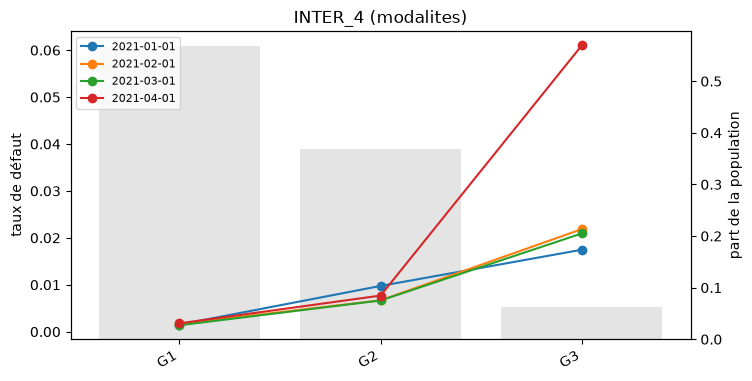

In [183]:
# Exemple : la variable avec la plus forte IV
v_top = synthese_lisible["Variable"][0]
print(comparaison.filter(pl.col("variable") == v_top))
display(bn.table_regle(train, v_top, TARGET, regles[v_top]))
bn.graphique_regle(train, v_top, TARGET, DATE_COL, regles[v_top])
plt.show()

### 4.7 bis Redondances après discrétisation

Une fois les variables découpées, nous comparons leurs classes deux à deux avec le V de Cramér. Si deux variables ont un V supérieur à 0,70, elles répartissent les clients presque de la même façon. Nous gardons alors celle qui a la meilleure IV.

Nous retirons aussi les variables dont l'IV est inférieure à 0,02, car elles ne distinguent pas les bons des mauvais clients.

In [184]:
# V de Cramér entre toutes les paires de variables découpées
toutes_paires = bn.redondances_classes(train, regles, seuil=0)
paires_cramer = toutes_paires.filter(pl.col("v_cramer") >= SEUIL_CRAMER)
print(f"Paires redondantes après discrétisation : {paires_cramer.height}")

Paires redondantes après discrétisation : 37


In [185]:
# Sélection : on garde la meilleure variable de chaque groupe redondant
selection = bn.selection_non_redondante(synthese, paires_cramer, iv_min=IV_MIN)
synthese_finale = bn.presenter_synthese(synthese, selection, iv_suspect=IV_SUSPECT)
VARS_MODELE = synthese_finale.filter(pl.col("Verdict").str.starts_with("retenue"))["Variable"].to_list()

print(synthese_finale.group_by("Verdict").len().sort("len", descending=True))
print(f"{len(VARS_MODELE)} variables candidates pour le modèle : {VARS_MODELE}")
display(synthese_finale)

shape: (13, 2)
┌─────────────────────────────────┬─────┐
│ Verdict                         ┆ len │
│ ---                             ┆ --- │
│ str                             ┆ u32 │
╞═════════════════════════════════╪═════╡
│ retenue                         ┆ 17  │
│ écartée : une seule classe      ┆ 15  │
│ retenue : IV élevée, vérifier … ┆ 5   │
│ écartée : redondante avec INTE… ┆ 4   │
│ écartée : redondante avec RATI… ┆ 3   │
│ écartée : redondante avec RECE… ┆ 3   │
│ écartée : redondante avec SOLD… ┆ 2   │
│ écartée : redondante avec CAUS… ┆ 1   │
│ écartée : redondante avec INTE… ┆ 1   │
│ écartée : redondante avec MINS… ┆ 1   │
│ écartée : redondante avec RECE… ┆ 1   │
│ écartée : redondante avec CRTA… ┆ 1   │
│ écartée : redondante avec NB_F… ┆ 1   │
└─────────────────────────────────┴─────┘
22 variables candidates pour le modèle : ['INTER_4', 'INTER_2', 'RECENCE_SAIN_MOIS', 'MINSOLDE_PAR', 'ENCOURS_PAR', 'NB_FENETRES_DFO_48M', 'CAUSE_SAIN_M0', 'CRTAD_AG_NBJDE_BB', 'RATIO_SOL

Variable,Méthode,Classes,IV train,IV test,Gini test,Pouvoir (Siddiqi),PSI max / mois,Stable / mois,Ordre conservé test,Verdict
str,str,i64,f64,f64,f64,str,f64,str,str,str
"""INTER_4""","""Modalités brutes""",3,1.06,1.03,0.5,"""suspect""",0.0,"""oui""","""oui""","""retenue : IV élevée, vérifier …"
"""INTER_2""","""Modalités brutes""",2,1.24,0.89,0.44,"""suspect""",0.0,"""oui""","""oui""","""retenue : IV élevée, vérifier …"
"""INTER_3""","""Modalités brutes""",2,1.24,0.89,0.44,"""suspect""",0.0,"""oui""","""oui""","""écartée : redondante avec INTE…"
"""INTER_5""","""Modalités brutes""",2,1.23,0.88,0.44,"""suspect""",0.001,"""oui""","""oui""","""écartée : redondante avec INTE…"
"""INTER_6""","""Modalités brutes""",2,1.23,0.88,0.44,"""suspect""",0.001,"""oui""","""oui""","""écartée : redondante avec INTE…"
"""RECENCE_SAIN_MOIS""","""Quantiles""",3,0.78,0.79,0.42,"""suspect""",0.001,"""oui""","""oui""","""retenue : IV élevée, vérifier …"
"""MINSOLDE_PAR""","""Quantiles""",3,0.72,0.77,0.4,"""suspect""",0.001,"""oui""","""oui""","""retenue : IV élevée, vérifier …"
"""ENCOURS_PAR""","""Arbre""",2,0.55,0.63,0.31,"""suspect""",0.0,"""oui""","""oui""","""retenue : IV élevée, vérifier …"
"""NB_FENETRES_DFO_48M""","""Modalités brutes""",2,0.63,0.49,0.19,"""fort""",0.0,"""oui""","""oui""","""retenue"""


In [186]:
# Enregistrement des découpages et des tables WoE pour le dossier de validation
SORTIES.mkdir(parents=True, exist_ok=True)
bn.sauver_regles(regles, SORTIES / "regles_binning.json")

regles_modele = {v: regles[v] for v in VARS_MODELE}
bn.tables_woe(train, regles_modele, TARGET).write_csv(SORTIES / "tables_woe.csv")

**Interprétation :** 

## 5. Modèles de scoring

### 5.1 Régression logistique

**Comment les variables entrent dans le modèle.** Chaque classe d'une variable découpée devient une variable indicatrice (0 ou 1). La **première classe** de chaque variable sert de **référence** : son coefficient vaut 0, et les autres classes sont comparées à elle. C'est ce qui permet ensuite de donner des points à chaque classe dans la grille de score.

**Précautions.**

- Si une indicatrice est exactement une combinaison des autres, nous la retirons avant l'estimation. Sinon, le modèle ne pourrait pas être estimé.
- Les lignes d'un même client ne sont pas indépendantes. Nous calculons donc des erreurs standard **robustes par client** (option `cluster` de statsmodels).

**Tests réalisés.**

- *Test global* : le modèle fait-il mieux qu'un modèle sans variable ? (rapport de vraisemblance)
- *Test par variable* : les classes d'une variable sont-elles significatives ensemble ? (test de Wald)
- *Test par classe* : chaque coefficient, avec son odds ratio et son intervalle de confiance à 95 %.
- *Monotonie* : les coefficients d'une variable doivent suivre l'ordre de ses classes.

Les fonctions ci-dessous sont définies une par une, puis utilisées pour le choix des variables.

In [187]:
# Classes de chaque variable, dans l'ordre du découpage (apprises sur le train)
modalites = {}
for v in VARS_MODELE:
    modalites[v] = bn.table_regle(train, v, TARGET, regles[v])["classe"].to_list()

In [188]:
def matrice_indicatrices(df, variables):
    # Une colonne 0/1 par classe ; la première classe de chaque variable est la référence (pas de colonne)
    colonnes = []
    for v in variables:
        classe = bn.appliquer_regle(df, v, regles[v])["classe"]
        for k in modalites[v][1:]:
            colonnes.append((classe == k).cast(pl.Float64).alias(f"{v} = {k}"))
    if not colonnes:
        return pl.DataFrame({"_vide": np.zeros(df.height)})
    return pl.DataFrame(colonnes)

In [189]:
def colonnes_independantes(X, tol=1e-7):
    # Repère les colonnes qui ne sont pas une combinaison des précédentes (décomposition QR)
    avec_constante = np.column_stack([np.ones(len(X)), X])
    r = np.abs(np.diag(np.linalg.qr(avec_constante, mode="r")))
    return r[1:] > tol * r.max()

In [190]:
def ajuster_logit(df, variables, robuste=True):
    # Régression logistique sur les indicatrices.
    # robuste=True : erreurs standard robustes par client ; robuste=False : estimation rapide
    X = matrice_indicatrices(df, variables)
    garder = colonnes_independantes(X.to_numpy())
    X = X.select([c for c, g in zip(X.columns, garder) if g])

    exog = sm.add_constant(pd.DataFrame(X.to_numpy(), columns=X.columns), has_constant="add")
    y = df[TARGET].to_numpy()

    if not robuste:
        return sm.Logit(y, exog).fit(disp=0, maxiter=500)

    groupes = pd.factorize(df[ID_COL].to_numpy())[0]
    return sm.Logit(y, exog).fit(disp=0, maxiter=500, cov_type="cluster", cov_kwds={"groups": groupes})

In [191]:
def predire(res, df, variables):
    # Probabilité de défaut prédite par le modèle res
    X = matrice_indicatrices(df, variables)
    noms = [c for c in res.params.index if c != "const"]
    manquantes = [c for c in noms if c not in X.columns]
    X = X.with_columns([pl.lit(0.0).alias(c) for c in manquantes]).select(noms)
    exog = sm.add_constant(pd.DataFrame(X.to_numpy(), columns=noms), has_constant="add")
    return np.asarray(res.predict(exog))

In [192]:
def tests_par_variable(res, variables):
    # Test de Wald : toutes les classes d'une variable sont-elles nulles ensemble ?
    noms = list(res.params.index)
    lignes = []
    for v in variables:
        positions = [i for i, n in enumerate(noms) if n.startswith(f"{v} = ")]
        if not positions:
            lignes.append({"variable": v, "ddl": 0, "chi2_wald": np.nan, "p_value": np.nan})
            continue
        R = np.zeros((len(positions), len(noms)))
        R[np.arange(len(positions)), positions] = 1
        w = res.wald_test(R, scalar=True)
        lignes.append({"variable": v, "ddl": len(positions),
                       "chi2_wald": float(w.statistic), "p_value": float(w.pvalue)})
    return pl.DataFrame(lignes).sort("p_value", descending=True, nulls_last=False)

#### Choix des variables : méthode pas à pas (stepwise)

Nous voulons une grille d'au plus **10 variables**. Nous les choisissons une par une :

1. nous partons d'un modèle vide ;
2. à chaque étape, nous essayons d'ajouter chacune des variables restantes ;
3. pour chaque essai, nous mesurons le **Gini du modèle par validation croisée** sur le train : le train est coupé en 5 blocs de clients, et chaque bloc est prédit par un modèle estimé sur les 4 autres ;
4. nous ajoutons la variable qui fait le plus monter ce Gini, **à condition qu'elle soit significative à 5 %** ;
5. nous nous arrêtons à 10 variables, ou avant si plus aucune variable n'améliore le Gini.

**Pourquoi la validation croisée ?** Nous n'avons pas d'échantillon de validation séparé. La validation croisée utilise tous les clients du train et donne une mesure fiable du Gini, sans utiliser le test pour choisir les variables.

In [193]:
# Modèle complet, avec toutes les variables candidates (pour comparaison)
res_complet = ajuster_logit(train, VARS_MODELE)

# Les 5 blocs de clients de la validation croisée
blocs = list(GroupKFold(n_splits=STEPWISE_CV_FOLDS).split(np.zeros(train.height),
                                                          groups=train[ID_COL].to_numpy()))

In [194]:
def gini_selection(variables):
    # Gini par validation croisée : chaque bloc est prédit par un modèle qui ne l'a pas vu
    p = np.zeros(train.height)
    for lignes_app, lignes_hors in blocs:
        res = ajuster_logit(train[lignes_app], variables, robuste=False)
        p[lignes_hors] = predire(res, train[lignes_hors], variables)
    return 2 * roc_auc_score(train[TARGET].to_numpy(), p) - 1

In [195]:
def essayer_candidates(retenues, candidates):
    # Gini obtenu en ajoutant chaque candidate au modèle actuel, du meilleur au moins bon
    essais = []
    for v in candidates:
        try:
            essais.append((gini_selection(retenues + [v]), v))
        except Exception:
            continue    # si le modèle ne converge pas, la variable est ignorée à cette étape
    return sorted(essais, reverse=True)

In [196]:
def choisir_ajout(essais, retenues, gini_actuel):
    # Première variable qui améliore le Gini ET qui est significative à 5 %
    for gini_v, v in essais:
        if gini_v - gini_actuel < GAIN_GINI_MIN:
            return None
        test_v = tests_par_variable(ajuster_logit(train, retenues + [v]), [v]).row(0, named=True)
        if test_v["ddl"] > 0 and test_v["p_value"] <= ALPHA:
            return gini_v, v, test_v["p_value"]
    return None

In [197]:
# Sélection pas à pas
VARS_FINALES = []
journal_stepwise = []
gini_actuel = 0.0
candidates = list(VARS_MODELE)

while candidates and len(VARS_FINALES) < NB_VARIABLES_MAX:
    essais = essayer_candidates(VARS_FINALES, candidates)
    ajout = choisir_ajout(essais, VARS_FINALES, gini_actuel)
    if ajout is None:
        break
    gini_actuel, v, p_v = ajout
    VARS_FINALES.append(v)
    candidates.remove(v)
    journal_stepwise.append({"etape": len(VARS_FINALES), "variable_ajoutee": v,
                             "gini_selection": gini_actuel, "p_value_wald": p_v})

display(pl.DataFrame(journal_stepwise))

etape,variable_ajoutee,gini_selection,p_value_wald
i64,str,f64,f64
1,"""INTER_4""",0.478286,6.0110e-84
2,"""INTER_2""",0.580182,3.0327e-25
3,"""ENCOURS_PAR""",0.626787,1.5580e-9
4,"""CAUSE_SAIN_M0""",0.656599,2.1820e-40
5,"""PART_VIE_CLIENT""",0.673164,0.014988
6,"""CODACVPRO_modif""",0.683492,0.000145
7,"""CRTAD_AG_NBJDE_BB""",0.692636,0.000028
8,"""RECENCE_ARR_MOIS""",0.69982,0.009804
9,"""solde_DAV_moyen""",0.702045,0.024268


In [198]:
# Modèle final, estimé sur tout le train avec des erreurs robustes par client
res_final = ajuster_logit(train, VARS_FINALES)

print(f"Modèle complet : {len(VARS_MODELE)} variables | modèle retenu : {len(VARS_FINALES)} variables")
print(f"Test global : LR = {res_final.llr:.1f} | p-value = {res_final.llr_pvalue:.2e} "
      f"| pseudo-R² de McFadden = {res_final.prsquared:.3f}")
display(tests_par_variable(res_final, VARS_FINALES))

Modèle complet : 22 variables | modèle retenu : 10 variables
Test global : LR = 758.3 | p-value = 9.29e-153 | pseudo-R² de McFadden = 0.172


variable,ddl,chi2_wald,p_value
str,i64,f64,f64
"""RATIO_ECR""",2,6.689673,0.035266
"""RECENCE_ARR_MOIS""",2,7.134598,0.028232
"""PART_VIE_CLIENT""",2,9.422884,0.008992
"""solde_DAV_moyen""",1,7.117413,0.007634
"""CRTAD_AG_NBJDE_BB""",1,7.153711,0.007481
"""CODACVPRO_modif""",1,12.405135,0.000428
"""INTER_2""",1,19.498251,0.00001
"""ENCOURS_PAR""",1,20.058249,0.000008
"""INTER_4""",2,31.301408,1.5958e-7


In [199]:
# Coefficients, odds ratios et intervalles de confiance à 95 %
ic = res_final.conf_int()
table_coef = pl.DataFrame({
    "terme": list(res_final.params.index),
    "coef": res_final.params.to_numpy(),
    "odds_ratio": np.exp(res_final.params.to_numpy()),
    "or_ic95_bas": np.exp(ic.iloc[:, 0].to_numpy()),
    "or_ic95_haut": np.exp(ic.iloc[:, 1].to_numpy()),
    "p_value": res_final.pvalues.to_numpy(),
})
display(table_coef)

terme,coef,odds_ratio,or_ic95_bas,or_ic95_haut,p_value
str,f64,f64,f64,f64,f64
"""const""",-5.550726,0.003885,0.00215,0.007018,1.5183e-75
"""INTER_4 = G2""",0.574642,1.776494,1.225824,2.574538,0.002401
"""INTER_4 = G3""",1.301913,3.676324,2.29336,5.893258,6.3964e-8
"""INTER_2 = G2""",0.816251,2.262004,1.574514,3.249679,0.00001
"""ENCOURS_PAR = ]2.2e+05 ; +inf]""",-0.950704,0.386469,0.254933,0.585873,0.000008
"""CAUSE_SAIN_M0 = G2""",1.624929,5.078056,3.668753,7.028724,1.1589e-22
"""PART_VIE_CLIENT = ]0.19 ; 0.46…",-0.238241,0.788013,0.558619,1.111605,0.174713
"""PART_VIE_CLIENT = ]0.46 ; +inf…",-0.468771,0.625771,0.461206,0.849055,0.002604
"""CODACVPRO_modif = G2""",0.52,1.682028,1.259396,2.246489,0.000428


In [200]:
def coefficients_monotones(res, v):
    # Les coefficients suivent-ils l'ordre des classes ? (référence = 0, classe manquante exclue)
    classes = [k for k in modalites[v] if k != "missing"]
    coefs = [0.0] + [res.params.get(f"{v} = {k}", np.nan) for k in classes[1:]]
    coefs = [c for c in coefs if not np.isnan(c)]
    ecarts = np.diff(coefs)
    return bool((ecarts >= 0).all() or (ecarts <= 0).all())

In [201]:
monotonie_coef = pl.DataFrame([
    {"variable": v, "monotonie_imposee": v not in NON_MONOTONES,
     "coefficients_monotones": coefficients_monotones(res_final, v)}
    for v in VARS_FINALES
])
display(monotonie_coef)

variable,monotonie_imposee,coefficients_monotones
str,bool,bool
"""INTER_4""",true,true
"""INTER_2""",true,true
"""ENCOURS_PAR""",true,true
"""CAUSE_SAIN_M0""",true,true
"""PART_VIE_CLIENT""",true,true
"""CODACVPRO_modif""",true,true
"""CRTAD_AG_NBJDE_BB""",true,true
"""RECENCE_ARR_MOIS""",true,true
"""solde_DAV_moyen""",true,true


**Interprétation :** à compléter.

- Quelles sont les 10 variables retenues, et dans quel sens jouent-elles ? Un odds ratio supérieur à 1 veut dire que la classe est plus risquée que la classe de référence.
- Y a-t-il des classes dont l'intervalle de confiance de l'odds ratio contient 1 ? Elles ne sont pas significatives seules, et nous pourrions les regrouper avec leur voisine.
- Y a-t-il des variables dont les coefficients ne sont pas monotones ? Cela vient souvent du lien avec une autre variable du modèle, et doit être expliqué.

### 5.2 Modèle concurrent : XGBoost

Le cours demande de comparer la régression logistique à un modèle concurrent. Nous utilisons XGBoost. Il sert de **point de comparaison** et ne sera **jamais retenu** comme modèle final, car il n'est pas assez explicable pour un usage réglementaire.

- XGBoost utilise les variables brutes, sans découpage. L'écart de Gini entre les deux modèles montre donc ce que la discrétisation et la simplicité de la logistique nous font perdre.
- XGBoost est entraîné sur le **train** ; l'entraînement s'arrête quand le Gini du **test** ne progresse plus.
- Nous n'utilisons pas `scale_pos_weight`, qui fausserait les probabilités sans améliorer le Gini.

In [202]:
VARS_XGB = VARS_QUANTI_31


def matrice_xgb(df):
    # Variables brutes au format numpy (XGBoost gère lui-même les valeurs manquantes)
    return df.select(pl.col(VARS_XGB).cast(pl.Float64)).to_numpy()

In [203]:
modele_xgb = XGBClassifier(
    n_estimators=2000,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=5,
    reg_alpha=0.1,
    eval_metric="auc",
    early_stopping_rounds=100,
    random_state=SEED,
    n_jobs=-1,
)
modele_xgb.fit(
    matrice_xgb(train), train[TARGET].to_numpy(),
    eval_set=[(matrice_xgb(test), test[TARGET].to_numpy())],
    verbose=False,
)
print("Nombre d'arbres retenus :", modele_xgb.best_iteration + 1)

Nombre d'arbres retenus : 247


### 5.3 Mesures de performance

| Mesure | Ce qu'elle mesure |
|---|---|
| **AUC** | la probabilité qu'un client en défaut ait un score plus risqué qu'un client sain (0,5 = hasard, 1 = parfait) |
| **Gini** | 2 × AUC − 1 : c'est la mesure principale du projet |
| **KS** | l'écart maximal entre la répartition des scores des sains et celle des défaillants |

Si le Gini du train est beaucoup plus élevé que celui du test, le modèle a sur-appris.

In [204]:
def metriques(y, p):
    # AUC, Gini et KS
    auc = roc_auc_score(y, p)
    fpr, tpr, _ = roc_curve(y, p)
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": float(np.max(tpr - fpr))}

In [205]:
y_train = train[TARGET].to_numpy()
y_test = test[TARGET].to_numpy()

predictions = {
    "Logistique complète": (
        predire(res_complet, train, VARS_MODELE),
        predire(res_complet, test, VARS_MODELE),
    ),
    "Logistique retenue (10 variables)": (
        predire(res_final, train, VARS_FINALES),
        predire(res_final, test, VARS_FINALES),
    ),
    "XGBoost (concurrent)": (
        modele_xgb.predict_proba(matrice_xgb(train))[:, 1],
        modele_xgb.predict_proba(matrice_xgb(test))[:, 1],
    ),
}

In [206]:
lignes = []
for nom, (p_train, p_test) in predictions.items():
    lignes.append({"modele": nom, "echantillon": "train", **metriques(y_train, p_train)})
    lignes.append({"modele": nom, "echantillon": "test", **metriques(y_test, p_test)})

tableau_perf = pl.DataFrame(lignes)
display(tableau_perf.pivot(on="echantillon", index="modele", values=["Gini", "AUC", "KS"]))

modele,Gini_train,Gini_test,AUC_train,AUC_test,KS_train,KS_test
str,f64,f64,f64,f64,f64,f64
"""Logistique complète""",0.71944,0.667776,0.85972,0.833888,0.563396,0.559202
"""Logistique retenue (10 variabl…",0.718022,0.666184,0.859011,0.833092,0.582473,0.548552
"""XGBoost (concurrent)""",0.800925,0.710735,0.900463,0.855368,0.640258,0.563987


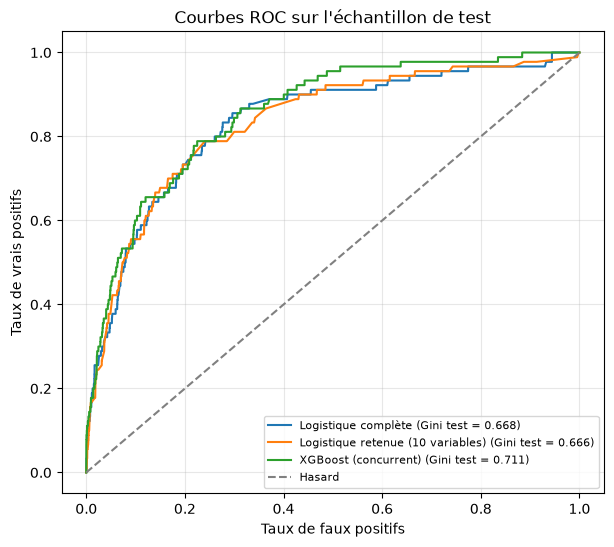

In [207]:
# Courbes ROC sur le test
fig, ax = plt.subplots(figsize=(7, 6))
for nom, (_, p_test) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, p_test)
    ax.plot(fpr, tpr, label=f"{nom} (Gini test = {metriques(y_test, p_test)['Gini']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Hasard")
ax.set_xlabel("Taux de faux positifs")
ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbes ROC sur l'échantillon de test")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

### AUC PR et prévalence

Le Gini (ou l'AUC ROC) ne dépend pas de la part de défauts. Or, dans un segment où les défauts sont rares, un modèle peut avoir un bon Gini tout en produisant beaucoup de faux positifs parmi les clients jugés les plus risqués. L'**AUC PR** (aire sous la courbe précision-rappel, calculée ici par la précision moyenne) mesure directement cela.

Sa valeur dépend de la **prévalence** (taux de défaut de l'échantillon) : un modèle tiré au hasard a une AUC PR égale à la prévalence. Pour comparer le train et le test, nous regardons donc aussi le **rapport AUC PR / prévalence** (gain par rapport au hasard) et l'**AUC PR normalisée** = (AUC PR − prévalence) / (1 − prévalence), qui vaut 0 pour un modèle tiré au hasard et 1 pour un modèle parfait.

In [ ]:
from sklearn.metrics import average_precision_score, precision_recall_curve

# Prévalence (taux de défaut) de chaque échantillon
prevalences = {"train": y_train.mean(), "test": y_test.mean()}
display(pl.DataFrame([
    {"echantillon": nom, "n": len(y), "n_defauts": int(y.sum()), "prevalence": y.mean()}
    for nom, y in (("train", y_train), ("test", y_test))
]))

# AUC PR (précision moyenne) par modèle et par échantillon, et gain par rapport au hasard
lignes = []
for nom, (p_train, p_test) in predictions.items():
    ligne = {"modele": nom}
    for ech, y, p in (("train", y_train, p_train), ("test", y_test, p_test)):
        auc_pr = average_precision_score(y, p)
        ligne[f"auc_pr_{ech}"] = auc_pr
        ligne[f"gain_{ech}"] = auc_pr / prevalences[ech]
        # AUC PR normalisée : (AUC PR - prévalence) / (1 - prévalence), 0 = hasard, 1 = parfait
        ligne[f"auc_pr_norm_{ech}"] = (auc_pr - prevalences[ech]) / (1 - prevalences[ech])
    lignes.append(ligne)
performance_pr = pl.DataFrame(lignes)
display(performance_pr)

# Courbes précision-rappel sur le test
fig, ax = plt.subplots(figsize=(7, 6))
for nom, (_, p_test) in predictions.items():
    precision, rappel, _ = precision_recall_curve(y_test, p_test)
    auc_pr_test = average_precision_score(y_test, p_test)
    auc_pr_norm_test = (auc_pr_test - prevalences["test"]) / (1 - prevalences["test"])
    ax.plot(rappel, precision,
            label=f"{nom} (AUC PR test = {auc_pr_test:.3f}, normalisée = {auc_pr_norm_test:.3f})")
ax.axhline(prevalences["test"], linestyle="--", color="grey",
           label=f"Hasard (prévalence = {prevalences['test']:.3%})")
ax.set_xlabel("Rappel (part des défauts détectés)")
ax.set_ylabel("Précision (part de défauts parmi les clients signalés)")
ax.set_title("Courbes précision-rappel sur l'échantillon de test")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

**Interprétation :** à compléter. Quel est le Gini de test de chaque modèle ? L'écart entre train et test est-il raisonnable ? Quel est l'écart entre XGBoost et la régression logistique retenue ?

### 5.4 Choix du modèle le plus simple

Nous comparons le modèle complet et le modèle à 10 variables avec l'AIC, le BIC et le Gini du train. Le Gini du test est affiché seulement pour information, puisque nous ne faisons aucun choix à partir du test.

In [208]:
lignes = []
for nom, res, variables, cle in (
    ("complet", res_complet, VARS_MODELE, "Logistique complète"),
    ("retenu (10 variables)", res_final, VARS_FINALES, "Logistique retenue (10 variables)"),
):
    lignes.append({
        "modele": nom,
        "nb_variables": len(variables),
        "nb_parametres": len(res.params),
        "AIC": res.aic,
        "BIC": res.bic,
        "gini_train": metriques(y_train, predictions[cle][0])["Gini"],
        "gini_test (info)": metriques(y_test, predictions[cle][1])["Gini"],
    })
comparaison_modeles = pl.DataFrame(lignes)
display(comparaison_modeles)

modele,nb_variables,nb_parametres,AIC,BIC,gini_train,gini_test (info)
str,i64,i64,f64,f64,f64,f64
"""complet""",22,32,3674.019255,3963.382,0.71944,0.667776
"""retenu (10 variables)""",10,15,3692.023372,3827.662158,0.718022,0.666184


**Décision.** Nous retenons le **modèle à 10 variables**. Chaque variable a été choisie pour ce qu'elle apporte au Gini, et toutes sont significatives à 5 %. Une grille de 10 variables reste facile à lire et plus stable dans le temps qu'un modèle avec toutes les variables. *À compléter avec l'écart de Gini par rapport au modèle complet.*

#### Essais pour améliorer le Gini

Nous avons testé plusieurs réglages pour essayer de dépasser un Gini de 0,70. Le choix se fait toujours sur le **Gini de sélection** (validation croisée sur le train). Le Gini du test n'est donné que pour information. Chaque essai sélectionne 10 variables.

| Réglage | Gini de sélection | Gini test (info) | Respecte le cours |
|---|---|---|---|
| Classes d'au moins 5 %, choix sur la validation seule, 1 croisement | 0,697 | 0,666 | oui |
| Classes d'au moins 3 % (validation seule) | 0,700 | 0,648 | oui |
| Classes d'au moins 2 % (validation seule) | 0,709 | 0,623 | oui, mais sur-apprentissage |
| Validation croisée, 1 croisement | 0,693 | 0,657 | oui |
| Validation croisée, 3 ou 6 croisements (sur 4 variables) | 0,701 | 0,657 | oui |
| **Validation croisée, 6 croisements (sur 5 variables) — retenu** | **0,704** | **0,666** | **oui** |
| Idem, avec au moins 10 défauts par classe | 0,710 | 0,674 | oui, mais WoE fragile |
| Idem, avec un écart entre classes d'au moins 15 % | 0,707 | 0,661 | non (règle des 30 %) |
| Idem, sans règle d'écart entre classes | 0,709 | 0,661 | non |
| *XGBoost (concurrent)* | — | *0,711* | *référence* |

**Ce que nous en retenons :**

- la régression logistique plafonne entre **0,66 et 0,68 en test**, quel que soit le réglage. Les écarts entre réglages (environ 0,01) sont plus petits que l'incertitude du Gini de test, qui ne repose que sur 90 défauts ;
- même sans la règle des 30 %, le Gini ne monte pas. Les règles de stabilité du cours ne sont donc pas ce qui nous limite ;
- l'écart d'environ 0,045 avec XGBoost est le prix à payer pour avoir un modèle explicable. Il nous paraît acceptable pour une grille de score réglementaire ;
- des classes plus fines améliorent le Gini sur l'échantillon qui sert à choisir, mais le font baisser sur le test : c'est du sur-apprentissage.

### 5.5 Le stepwise par ordre de liaison

C'est la méthode que nous avons utilisée en 5.1. Les variables candidates sont déjà classées par IV et débarrassées des redondances (partie 4). À chaque étape, nous ajoutons celle qui apporte le plus de Gini, à condition qu'elle soit significative.

## 6. Grille de score

### 6.1 De la probabilité au score

La régression logistique donne, pour chaque client, le logarithme de son rapport « défaut / non-défaut ». En changeant le signe, nous obtenons un score : plus il est élevé, moins le client est risqué. Transformer ce score de façon linéaire ne change pas l'ordre des clients, donc ne change pas le Gini.

### 6.2 La méthode du PDO (Points to Double the Odds)

- Facteur = PDO / ln(2)
- Offset = Score_ref − Facteur × ln(Odds_ref)
- Points d'une classe = − Facteur × coefficient de la classe + (Offset − Facteur × constante) / nombre de variables

Avec nos paramètres (PDO = 20, Score_ref = 600, Odds_ref = 50), un client qui a 20 points de plus a deux fois plus de chances de ne pas faire défaut.

In [209]:
facteur = PDO / np.log(2)
offset = SCORE_REF - facteur * np.log(ODDS_REF)
constante = res_final.params["const"]
nb_vars = len(VARS_FINALES)

print(f"Facteur = {facteur:.2f} | Offset = {offset:.2f}")

Facteur = 28.85 | Offset = 487.12


In [210]:
# Grille : les points de chaque classe de chaque variable
lignes = []
for v in VARS_FINALES:
    for k in modalites[v]:
        coef = float(res_final.params.get(f"{v} = {k}", 0.0))   # la classe de référence vaut 0
        points = -facteur * coef + (offset - facteur * constante) / nb_vars
        lignes.append({"variable": v, "classe": k, "coef": coef, "points": points})

grille = pl.DataFrame(lignes).with_columns(points_pdo=pl.col("points").round(0).cast(pl.Int64))
display(grille)

variable,classe,coef,points,points_pdo
str,str,f64,f64,i64
"""INTER_4""","""G1""",0.0,64.728298,65
"""INTER_4""","""G2""",0.574642,48.147644,48
"""INTER_4""","""G3""",1.301913,27.163016,27
"""INTER_2""","""G1""",0.0,64.728298,65
"""INTER_2""","""G2""",0.816251,41.176264,41
"""ENCOURS_PAR""","""]-inf ; 2.2e+05]""",0.0,64.728298,65
"""ENCOURS_PAR""","""]2.2e+05 ; +inf]""",-0.950704,92.159824,92
"""CAUSE_SAIN_M0""","""G1""",0.0,64.728298,65
"""CAUSE_SAIN_M0""","""G2""",1.624929,17.84277,18


In [211]:
def score_grille(df, colonne):
    # Score d'un client = somme des points de ses classes
    total = np.zeros(df.height)
    for v in VARS_FINALES:
        g = grille.filter(pl.col("variable") == v)
        points = dict(zip(g["classe"].to_list(), g[colonne].cast(pl.Float64).to_list()))
        points_reference = points[modalites[v][0]]
        classe = bn.appliquer_regle(df, v, regles[v])["classe"]
        total += classe.replace_strict(points, default=points_reference, return_dtype=pl.Float64).to_numpy()
    return total

In [212]:
# Contrôle : la somme des points (avant arrondi) doit redonner exactement le score du modèle
pd_retenu_train = predictions["Logistique retenue (10 variables)"][0]
score_modele = offset + facteur * np.log((1 - pd_retenu_train) / pd_retenu_train)
ecart_max = np.max(np.abs(score_modele - score_grille(train, "points")))
print(f"Écart maximal entre le score du modèle et la somme des points : {ecart_max:.2e}")

Écart maximal entre le score du modèle et la somme des points : 2.27e-13


### 6.3 Autre méthode : la normalisation des coefficients

Pour chaque variable, la classe la plus risquée reçoit 0 point. Les autres classes reçoivent des points proportionnels à leur écart avec cette classe. L'échelle est réglée pour que le meilleur profil possible obtienne **1 000 points**.

### 6.4 Comparaison des deux méthodes

Les deux grilles classent les clients exactement dans le même ordre, aux arrondis près, donc elles ont le même Gini. Elles se distinguent seulement par leur lecture :

- avec le PDO, les points se traduisent directement en rapport de chances, ce qui facilite le calibrage ;
- avec la normalisation, l'échelle va de 0 à 1 000, ce qui est très parlant pour les conseillers.

**Nous retenons la grille PDO**, parce qu'elle se relie directement au risque.

In [213]:
# Grille normalisée (de 0 à 1 000 points)
amplitudes = grille.group_by("variable").agg(coef_max=pl.col("coef").max(), coef_min=pl.col("coef").min())
total_amplitude = (amplitudes["coef_max"] - amplitudes["coef_min"]).sum()

grille = (
    grille.join(amplitudes, on="variable", how="left")
    .with_columns(points_normalises=(1000 * (pl.col("coef_max") - pl.col("coef")) / total_amplitude)
                  .round(0).cast(pl.Int64))
    .drop("coef_max", "coef_min")
)

In [214]:
# Scores des clients avec la grille PDO
score_train = score_grille(train, "points_pdo")
score_test = score_grille(test, "points_pdo")

In [215]:
# Comparaison des deux grilles
lignes = []
for nom, colonne in (("PDO", "points_pdo"), ("Normalisation", "points_normalises")):
    s_train = score_grille(train, colonne)
    s_test = score_grille(test, colonne)
    lignes.append({
        "methode": nom,
        "score_min": s_train.min(),
        "score_max": s_train.max(),
        "gini_train": metriques(y_train, -s_train)["Gini"],
        "gini_test": metriques(y_test, -s_test)["Gini"],
    })
display(pl.DataFrame(lignes))

grille.write_csv(SORTIES / "grille_score.csv")

methode,score_min,score_max,gini_train,gini_test
str,f64,f64,f64,f64
"""PDO""",516.0,729.0,0.717466,0.664711
"""Normalisation""",0.0,1002.0,0.718393,0.66573


**Interprétation :** à compléter. Entre quelles valeurs le score varie-t-il ? Les deux grilles ont-elles bien le même Gini ? Un petit écart vient seulement de l'arrondi des points.

## 7. Classes homogènes de risque (CHR)

### 7.1 Construction des classes

Nous regroupons les clients en quelques classes de risque à partir de leur score. Pour cela, nous appliquons **les mêmes règles que pour la discrétisation des variables** :

- au départ, le score est coupé en 20 tranches de même taille ;
- les tranches voisines sont regroupées jusqu'à ce que chaque classe contienne au moins 5 % des clients et 20 défauts ;
- le risque doit augmenter régulièrement d'une classe à l'autre ;
- deux classes voisines doivent avoir au moins **30 % d'écart de risque, chaque mois**.

Cette méthode remplace les deux méthodes de la première version : `optbinning`, qui ne vérifiait pas la stabilité mois par mois, et le regroupement manuel de 8 classes en 4, qui ne fonctionnait plus dès que le nombre de classes changeait.

Par convention, la **CHR 1 est la moins risquée**.

In [216]:
SCORE = "SCORE"
pd_train = predictions["Logistique retenue (10 variables)"][0]
pd_test = predictions["Logistique retenue (10 variables)"][1]

# Ajout du score et de la probabilité de défaut aux bases
train_s = train.with_columns(pl.Series(SCORE, score_train), pl.Series("PD_LR", pd_train))
test_s = test.with_columns(pl.Series(SCORE, score_test), pl.Series("PD_LR", pd_test))

In [217]:
# Découpage du score en classes, avec les règles du cours
regle_chr = bn.regle_par_methode(
    train_s, SCORE, TARGET, "quantiles", DATE_COL,
    n_bins=20, part_min=PART_MIN, defauts_min=DEFAUTS_MIN, ecart_min=ECART_MIN, monotone=True,
)
print("Bornes de score :", regle_chr["bornes"])

Bornes de score : [596.0, 637.0, 659.0]


In [218]:
# Noms des classes : la CHR 1 correspond aux scores les plus élevés (les moins risqués)
libelles_chr = bn.table_regle(train_s, SCORE, TARGET, regle_chr)["classe"].to_list()
NB_CHR = len(libelles_chr)
CHR_DE = {libelle: f"CHR {NB_CHR - i}" for i, libelle in enumerate(libelles_chr)}
ORDRE_CHR = [f"CHR {k}" for k in range(1, NB_CHR + 1)]
print(f"Nombre de CHR : {NB_CHR}")

Nombre de CHR : 4


In [219]:
def ajouter_chr(df):
    # Ajoute la colonne CHR à partir du score
    classe = bn.appliquer_regle(df, SCORE, regle_chr)["classe"]
    return df.with_columns(classe.replace_strict(CHR_DE, default=None, return_dtype=pl.String).alias("CHR"))

In [220]:
def table_chr(df):
    # Effectif, défauts, taux de défaut et bornes de score de chaque CHR
    return (
        df.group_by("CHR")
        .agg(
            n=pl.len(),
            n_defaut=pl.col(TARGET).sum(),
            taux_defaut=pl.col(TARGET).mean(),
            pd_moyenne_lr=pl.col("PD_LR").mean(),
            score_min=pl.col(SCORE).min(),
            score_max=pl.col(SCORE).max(),
        )
        .with_columns(part_population=pl.col("n") / df.height)
        .sort(pl.col("CHR").str.extract(r"(\d+)").cast(pl.Int64))
    )

In [221]:
train_s = ajouter_chr(train_s)
test_s = ajouter_chr(test_s)

print("Train")
display(table_chr(train_s))
print("Test")
display(table_chr(test_s))

Train


CHR,n,n_defaut,taux_defaut,pd_moyenne_lr,score_min,score_max,part_population
str,u32,f64,f64,f64,f64,f64,f64
"""CHR 1""",36657,32.0,0.000873,0.001182,660.0,729.0,0.586709
"""CHR 2""",13221,49.0,0.003706,0.003487,638.0,659.0,0.211607
"""CHR 3""",9424,127.0,0.013476,0.012438,597.0,637.0,0.150835
"""CHR 4""",3177,151.0,0.047529,0.047954,516.0,596.0,0.050849


Test


CHR,n,n_defaut,taux_defaut,pd_moyenne_lr,score_min,score_max,part_population
str,u32,f64,f64,f64,f64,f64,f64
"""CHR 1""",9287,12.0,0.001292,0.001189,660.0,729.0,0.593836
"""CHR 2""",3278,13.0,0.003966,0.003495,638.0,659.0,0.209604
"""CHR 3""",2284,31.0,0.013573,0.012549,597.0,637.0,0.146045
"""CHR 4""",790,34.0,0.043038,0.047373,516.0,596.0,0.050515


**Interprétation :** Nous obtenons 4 CHR

### 7.2 Stabilité des classes dans le temps

- **Stabilité du risque** : l'écart avec la classe suivante doit rester d'au moins 30 % chaque mois. Une valeur négative signale une inversion.
- **Stabilité des volumes** : le PSI mensuel doit rester inférieur à 0,10.

In [222]:
print("Stabilité mois par mois (train) :")
display(bn.stabilite_regle(train_s, SCORE, TARGET, DATE_COL, regle_chr))

print("Stabilité mois par mois (test) :")
display(bn.stabilite_regle(test_s, SCORE, TARGET, DATE_COL, regle_chr))

Stabilité mois par mois (train) :


classe,taux_2021-01-01,taux_2021-02-01,taux_2021-03-01,taux_2021-04-01,ecart_min_suivante
str,f64,f64,f64,f64,f64
"""]-inf ; 596]""",0.038601,0.031704,0.029494,0.084187,1.322972
"""]596 ; 637]""",0.016617,0.013091,0.010837,0.013322,1.782681
"""]637 ; 659]""",0.003665,0.002714,0.003649,0.004788,1.470115
"""]659 ; +inf]""",0.000547,0.001099,0.000776,0.001064,NaN


Stabilité mois par mois (test) :


classe,taux_2021-01-01,taux_2021-02-01,taux_2021-03-01,taux_2021-04-01,ecart_min_suivante
str,f64,f64,f64,f64,f64
"""]-inf ; 596]""",0.031915,0.046512,0.034146,0.057778,1.25
"""]596 ; 637]""",0.014184,0.008389,0.013592,0.018062,0.711409
"""]637 ; 659]""",0.003472,0.004902,0.003769,0.003741,1.162095
"""]659 ; +inf]""",0.00128,0.001285,0.000871,0.00173,NaN


PSI mensuel maximal (train) : 0.0004
L'ordre des CHR est-il le même sur le test ? True


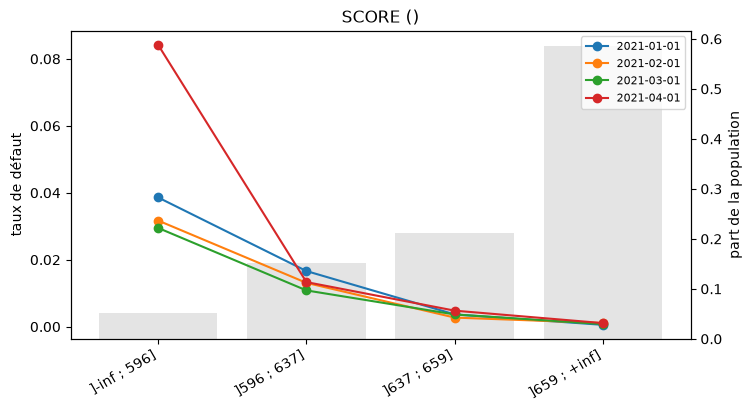

In [223]:
psi_chr = bn.psi_mensuel(train_s, SCORE, regle_chr, DATE_COL)
table_train_chr = bn.table_regle(train_s, SCORE, TARGET, regle_chr)
table_test_chr = bn.table_regle(test_s, SCORE, TARGET, regle_chr)

print(f"PSI mensuel maximal (train) : {psi_chr:.4f}")
print("L'ordre des CHR est-il le même sur le test ?", bn.meme_ordre(table_train_chr, table_test_chr))

bn.graphique_regle(train_s, SCORE, TARGET, DATE_COL, regle_chr)
plt.show()

**Interprétation :** à compléter. Les écarts restent-ils supérieurs à 30 % chaque mois ? Le PSI est-il inférieur à 0,10 ? Comme le test ne compte qu'environ 90 défauts, une petite inversion entre deux classes voisines peut venir du hasard.

### 7.3 Homogénéité à l'intérieur des classes

À l'intérieur d'une même CHR, le risque ne devrait pas beaucoup varier selon une variable qui n'est pas dans le modèle. Nous prenons l'ancienneté de la relation, coupée en deux (48 mois ou moins, plus de 48 mois), comme dans la segmentation.

In [224]:
VAR_EXOGENE = "ANCIENNETE_modif"

if VAR_EXOGENE in VARS_FINALES:
    print(f"Attention : {VAR_EXOGENE} est dans le modèle, il faudrait choisir une autre variable.")

if VAR_EXOGENE in train_s.columns:
    tranche = pl.when(pl.col(VAR_EXOGENE) <= 48).then(pl.lit("48 mois ou moins")).otherwise(pl.lit("plus de 48 mois"))
    homogeneite = (
        train_s.with_columns(tranche=tranche)
        .group_by("CHR", "tranche")
        .agg(n=pl.len(), taux=pl.col(TARGET).mean())
        .pivot(on="tranche", index="CHR", values=["n", "taux"])
        .sort(pl.col("CHR").str.extract(r"(\d+)").cast(pl.Int64))
    )
    display(homogeneite)

CHR,n_48 mois ou moins,n_plus de 48 mois,taux_48 mois ou moins,taux_plus de 48 mois
str,u32,u32,f64,f64
"""CHR 1""",2674,33983,0.000748,0.000883
"""CHR 2""",2565,10656,0.004678,0.003472
"""CHR 3""",3097,6327,0.013239,0.013593
"""CHR 4""",1805,1372,0.033241,0.066327


**Interprétation :** On remarque que dans chaque CHR, les taux de defauts relativement à la variable exogène sont les approximativement les memes.

### 7.4 Différence de risque entre les classes

Pour chaque paire de CHR voisines, nous testons si leurs taux de défaut sont différents (test du chi²). Une p-value faible montre que les deux classes sont bien distinctes.

In [225]:
def tests_adjacents(df):
    # Test du chi² entre chaque CHR et la suivante
    t = table_chr(df)
    lignes_t = list(t.iter_rows(named=True))
    resultats = []
    for a, b in zip(lignes_t, lignes_t[1:]):
        tableau = [[a["n_defaut"], a["n"] - a["n_defaut"]],
                   [b["n_defaut"], b["n"] - b["n_defaut"]]]
        p = stats.chi2_contingency(tableau)[1] if min(map(sum, tableau)) > 0 else np.nan
        resultats.append({"paire": f"{a['CHR']} / {b['CHR']}",
                          "taux_1": a["taux_defaut"], "taux_2": b["taux_defaut"], "p_value": p})
    return pl.DataFrame(resultats)

In [226]:
print("Train")
display(tests_adjacents(train_s))
print("Test")
display(tests_adjacents(test_s))

Train


paire,taux_1,taux_2,p_value
str,f64,f64,f64
"""CHR 1 / CHR 2""",0.000873,0.003706,9.7586e-12
"""CHR 2 / CHR 3""",0.003706,0.013476,2.9419e-16
"""CHR 3 / CHR 4""",0.013476,0.047529,2.8793e-29


Test


paire,taux_1,taux_2,p_value
str,f64,f64,f64
"""CHR 1 / CHR 2""",0.001292,0.003966,0.006422
"""CHR 2 / CHR 3""",0.003966,0.013573,0.000131
"""CHR 3 / CHR 4""",0.013573,0.043038,0.000001


### 7.5 Échelle maître

L'échelle maître rassemble les CHR de tous les segments sur une même échelle de probabilité de défaut. Comme elle repose sur la probabilité de défaut de chaque CHR, nous l'appliquons après le calibrage, en partie **8.8**.

### 7.6 Information perdue en passant aux classes

En regroupant les clients en quelques classes, nous perdons un peu de précision. Pour mesurer cette perte, nous comparons le Gini du score à celui des CHR, en utilisant le taux de défaut de chaque CHR comme score.

In [227]:
taux_par_chr = dict(zip(table_chr(train_s)["CHR"].to_list(), table_chr(train_s)["taux_defaut"].to_list()))

lignes = []
for nom, df in (("train", train_s), ("test", test_s)):
    y = df[TARGET].to_numpy()
    score_chr = df["CHR"].replace_strict(taux_par_chr, return_dtype=pl.Float64).to_numpy()
    lignes.append({
        "echantillon": nom,
        "gini_score": metriques(y, -df[SCORE].to_numpy())["Gini"],
        "gini_chr": metriques(y, score_chr)["Gini"],
    })
perte = pl.DataFrame(lignes).with_columns(perte=pl.col("gini_score") - pl.col("gini_chr"))
display(perte)

echantillon,gini_score,gini_chr,perte
str,f64,f64,f64
"""train""",0.717466,0.683288,0.034178
"""test""",0.664711,0.62486,0.03985


## 8. Calibrage : du score à la probabilité de défaut

### 8.1 à 8.3 L'idée

- Le Gini mesure si les clients sont **bien classés**. Le calibrage vérifie que la probabilité de défaut de chaque classe est **juste en niveau**.
- Le taux de défaut observé sur une courte période ne suffit pas : il dépend de la conjoncture du moment, et il est imprécis quand il y a peu de défauts.
- La réglementation demande une probabilité de défaut de **long terme** (« Through-the-Cycle »), qui ne dépend pas de la conjoncture du moment.

### 8.4 La moyenne de long terme (LRA)

Pour chaque CHR, la probabilité de défaut est la **moyenne des taux de défaut mensuels** de la classe. Chaque mois compte autant, quel que soit son nombre de clients.

**Limite importante :** nous n'avons que quatre mois d'historique, alors qu'une vraie moyenne de long terme couvre au moins cinq ans. Nous compensons en partie avec une marge de prudence (8.7).

### 8.5 Les méthodes comparées

| Méthode | Probabilité de défaut de la classe |
|---|---|
| Fréquence observée | nombre de défauts divisé par le nombre de clients de la classe |
| **Moyenne de long terme (retenue)** | moyenne des taux mensuels de la classe |
| Régression logistique | moyenne des probabilités prédites par le modèle dans la classe |

Nous n'utilisons pas la régression isotone ni les méthodes bayésiennes : avec une seule période courte, elles ne corrigeraient pas l'effet de la conjoncture.

In [228]:
# Taux de défaut de chaque CHR, mois par mois
mensuel = (
    train_s.group_by("CHR", DATE_COL)
    .agg(n=pl.len(), d=pl.col(TARGET).sum())
    .with_columns(taux=pl.col("d") / pl.col("n"))
)
lra = mensuel.group_by("CHR").agg(pd_lra=pl.col("taux").mean(), nb_mois=pl.len())

In [229]:
# Les trois probabilités de défaut côte à côte
calibrage = (
    table_chr(train_s)
    .select("CHR", "n", "n_defaut", "taux_defaut", "pd_moyenne_lr")
    .rename({"taux_defaut": "pd_frequence", "pd_moyenne_lr": "pd_logistique"})
    .join(lra, on="CHR")
    .sort(pl.col("CHR").str.extract(r"(\d+)").cast(pl.Int64))
)
display(calibrage)

CHR,n,n_defaut,pd_frequence,pd_logistique,pd_lra,nb_mois
str,u32,f64,f64,f64,f64,u32
"""CHR 1""",36657,32.0,0.000873,0.001182,0.000872,4
"""CHR 2""",13221,49.0,0.003706,0.003487,0.003704,4
"""CHR 3""",9424,127.0,0.013476,0.012438,0.013467,4
"""CHR 4""",3177,151.0,0.047529,0.047954,0.045996,4


### 8.6 Vérification du calibrage

Sur le **test**, nous comparons la probabilité de défaut de chaque CHR au taux de défaut réellement observé :

- un **test binomial** par classe vérifie que la probabilité n'est pas sous-estimée (une p-value inférieure à 5 % signale une sous-estimation) ;
- le **score de Brier** mesure l'écart moyen entre la probabilité prédite et ce qui s'est passé. Sa **décomposition de Murphy** le découpe en trois parties :
  - la *fiabilité* : l'écart entre probabilités et taux observés, qui doit être faible ;
  - la *résolution* : la capacité des classes à séparer les risques, qui doit être forte ;
  - l'*incertitude* : la part qui dépend seulement du taux de défaut moyen ;
- un **graphique** compare les probabilités prédites aux taux observés.

In [230]:
# Probabilité de défaut (LRA) de chaque CHR, appliquée au test
pd_lra = dict(zip(calibrage["CHR"].to_list(), calibrage["pd_lra"].to_list()))

verif = (
    table_chr(test_s)
    .select("CHR", "n", "n_defaut", "taux_defaut")
    .with_columns(pd_lra=pl.col("CHR").replace_strict(pd_lra, return_dtype=pl.Float64))
)

In [231]:
# Test binomial : la probabilité de défaut est-elle sous-estimée ?
p_binomial = [float(stats.binom.sf(d - 1, n, p)) for d, n, p in verif.select("n_defaut", "n", "pd_lra").iter_rows()]
verif = verif.with_columns(p_binomial_sous_estimation=pl.Series(p_binomial))
display(verif)

CHR,n,n_defaut,taux_defaut,pd_lra,p_binomial_sous_estimation
str,u32,f64,f64,f64,f64
"""CHR 1""",9287,12.0,0.001292,0.000872,0.118707
"""CHR 2""",3278,13.0,0.003966,0.003704,0.440214
"""CHR 3""",2284,31.0,0.013573,0.013467,0.506906
"""CHR 4""",790,34.0,0.043038,0.045996,0.677913


In [232]:
# Score de Brier et décomposition de Murphy
y_t = test_s[TARGET].to_numpy()
pd_t = test_s["CHR"].replace_strict(pd_lra, return_dtype=pl.Float64).to_numpy()
taux_moyen = y_t.mean()

brier = np.mean((pd_t - y_t) ** 2)
fiabilite = float((verif["n"] * (verif["pd_lra"] - verif["taux_defaut"]) ** 2).sum() / len(y_t))
resolution = float((verif["n"] * (verif["taux_defaut"] - taux_moyen) ** 2).sum() / len(y_t))
incertitude = taux_moyen * (1 - taux_moyen)

print(f"Brier = {brier:.6f}")
print(f"Fiabilité = {fiabilite:.2e} | Résolution = {resolution:.2e} | Incertitude = {incertitude:.2e}")
print(f"Contrôle : fiabilité − résolution + incertitude = {fiabilite - resolution + incertitude:.6f}")

Brier = 0.005631
Fiabilité = 5.63e-07 | Résolution = 9.16e-05 | Incertitude = 5.72e-03
Contrôle : fiabilité − résolution + incertitude = 0.005631


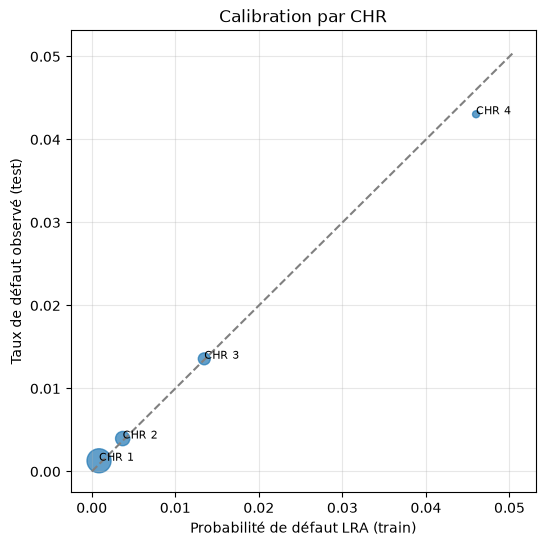

In [233]:
# Graphique de calibration
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(verif["pd_lra"], verif["taux_defaut"], s=verif["n"] / verif["n"].max() * 300, alpha=0.7)
for nom_chr, x, y in verif.select("CHR", "pd_lra", "taux_defaut").iter_rows():
    ax.annotate(nom_chr, (x, y), fontsize=8)
borne = max(verif["pd_lra"].max(), verif["taux_defaut"].max()) * 1.1
ax.plot([0, borne], [0, borne], linestyle="--", color="grey")
ax.set_xlabel("Probabilité de défaut LRA (train)")
ax.set_ylabel("Taux de défaut observé (test)")
ax.set_title("Calibration par CHR")
ax.grid(alpha=0.3)
plt.show()

**Interprétation :** à compléter. Une CHR est-elle sous-estimée (p-value binomiale inférieure à 5 %) ? Quelle est la part de la fiabilité dans le score de Brier ? Les points sont-ils proches de la diagonale ?

### 8.7 De la probabilité calibrée à la probabilité réglementaire

La probabilité réglementaire de chaque CHR est :

**PD réglementaire = maximum entre (PD LRA + marges de prudence) et 0,05 %**

| Marge | Ce qu'elle couvre | Comment nous la fixons |
|---|---|---|
| **A** | les défauts des données (seulement 4 mois d'historique, hausse inexpliquée d'avril) | `MOC_A`, à fixer à dire d'expert (0 pour l'instant) |
| **B** | les choix de méthode (moyenne sur une période courte, pas d'échantillon hors période) | `MOC_B`, à fixer à dire d'expert (0 pour l'instant) |
| **C** | l'erreur d'estimation statistique | borne haute de l'intervalle de Jeffreys à 90 %, moins le taux observé. Plus une classe a peu de défauts, plus cette marge est grande |

Nous vérifions enfin que les probabilités finales augmentent bien de la CHR 1 à la dernière.

In [234]:
# Marge de catégorie C : borne de Jeffreys à 90 % moins le taux observé
moc_c = [float(stats.beta.ppf(NIVEAU_MOC_C, d + 0.5, n - d + 0.5)) - d / n
         for d, n in calibrage.select("n_defaut", "n").iter_rows()]

pd_reglementaire = calibrage.with_columns(moc_c=pl.Series(moc_c))
pd_reglementaire = pd_reglementaire.with_columns(
    pd_reglementaire=pl.max_horizontal(pl.col("pd_lra") + MOC_A + MOC_B + pl.col("moc_c"), pl.lit(PD_PLANCHER))
)
display(pd_reglementaire.select("CHR", "n", "n_defaut", "pd_lra", "moc_c", "pd_reglementaire"))

CHR,n,n_defaut,pd_lra,moc_c,pd_reglementaire
str,u32,f64,f64,f64,f64
"""CHR 1""",36657,32.0,0.000872,0.000218,0.001089
"""CHR 2""",13221,49.0,0.003704,0.000732,0.004436
"""CHR 3""",9424,127.0,0.013467,0.001597,0.015064
"""CHR 4""",3177,151.0,0.045996,0.005043,0.051039


In [235]:
pd_finales = pd_reglementaire["pd_reglementaire"].to_numpy()
print("Les probabilités augmentent-elles de la CHR 1 à la dernière ?", bool(np.all(np.diff(pd_finales) >= 0)))
pd_reglementaire.write_csv(SORTIES / "pd_par_chr.csv")

Les probabilités augmentent-elles de la CHR 1 à la dernière ? True


### 8.8 Projection sur l'échelle maître (7.5)

L'échelle maître est **commune à tous les segments** : chaque segment garde ses propres CHR, mais leurs probabilités de défaut sont rangées sur une même grille de grades. Deux clients de segments différents ayant le même grade ont ainsi un niveau de risque comparable.

- Les grades sont définis par des **bornes de probabilité de défaut qui doublent** d'un grade au suivant (0,05 %, 0,1 %, 0,2 %, …, 25,6 %), soit 11 grades.
- Une CHR reçoit le grade g si **pd_min < PD réglementaire ≤ pd_max**.
- La première borne (0,05 %) correspond au plancher réglementaire : une CHR au plancher tombe dans le grade 1.

In [ ]:
# Grades de l'échelle maître
display(em.echelle_maitre())

In [ ]:
# Grade de chaque CHR, à partir de sa probabilité de défaut réglementaire
grades_chr = pd_reglementaire.select("CHR", "n", "n_defaut", "pd_reglementaire").with_columns(
    grade=pl.Series(em.affecter_grade(pd_finales))
)
display(grades_chr)
print("Les grades augmentent-ils de la CHR 1 à la dernière ?", bool(np.all(np.diff(grades_chr["grade"].to_numpy()) >= 0)))
print("Des CHR partagent-elles un même grade ?", grades_chr["grade"].n_unique() < grades_chr.height)
grades_chr.write_csv(SORTIES / "grade_par_chr.csv")

**Interprétation :** à compléter. Combien de grades le segment occupe-t-il ? Si deux CHR tombent dans le même grade, l'échelle maître ne les distingue plus : faut-il l'accepter (écart de risque faible) ou revoir les bornes ?

## 9. Suivi dans le temps (pour culture)

- **Gini par mois** : nous vérifions que le score classe bien les clients sur chacun des mois.
- **PSI** : nous comparons la répartition des clients entre les CHR sur le train et sur le test, globalement et mois par mois. Un PSI inférieur à 0,10 indique une population stable, entre 0,10 et 0,25 il faut surveiller, au-delà de 0,25 la population a changé.

In [236]:
def psi(p, q, eps=1e-6):
    # Indice de stabilité de la population entre deux répartitions p et q
    return float(np.sum((q - p) * np.log((q + eps) / (p + eps))))

In [237]:
def repartition(df):
    # Part des clients dans chaque CHR, dans l'ordre CHR 1, CHR 2, ...
    t = df.group_by("CHR").len()
    effectifs = dict(zip(t["CHR"].to_list(), t["len"].to_list()))
    return np.array([effectifs.get(c, 0) for c in ORDRE_CHR]) / df.height

In [238]:
reference = repartition(train_s)

lignes = [{"periode": "test (global)",
           "psi_vs_train": psi(reference, repartition(test_s)),
           "gini": metriques(y_test, -score_test)["Gini"]}]

for (periode,), d in sorted(test_s.group_by(DATE_COL), key=lambda x: x[0]):
    y_p = d[TARGET].to_numpy()
    gini_p = metriques(y_p, -d[SCORE].to_numpy())["Gini"] if 0 < y_p.sum() < len(y_p) else np.nan
    lignes.append({"periode": str(periode), "psi_vs_train": psi(reference, repartition(d)), "gini": gini_p})

display(pl.DataFrame(lignes))

periode,psi_vs_train,gini
str,f64,f64
"""test (global)""",0.000262,0.664711
"""2021-01-01""",0.000957,0.614064
"""2021-02-01""",0.00123,0.652988
"""2021-03-01""",0.002357,0.627459
"""2021-04-01""",0.001125,0.721668


**Interprétation :** à compléter. Le Gini reste-t-il stable d'un mois à l'autre ? Le PSI reste-t-il faible ? Avec 20 à 25 défauts par mois dans le test, le Gini mensuel varie beaucoup : seule une baisse nette et répétée serait inquiétante.

**Tests de résistance et matrices de migration (9.4)** : nous ne les traitons pas, faute d'un historique assez long pour observer les passages d'une classe à l'autre.

## 10. Enjeux avancés

- **Explicabilité.** Notre grille de score s'explique d'elle-même : chaque point est lié à une classe d'une variable. Des outils comme SHAP ou LIME ne seraient utiles que pour expliquer XGBoost.
- **Biais et équité.** L'âge peut faire partie du score (partie 2.5). Avant une mise en production, il faudrait vérifier qu'à risque égal, une tranche d'âge n'est pas pénalisée plus que les autres.
- **Machine learning ou modèle classique.** XGBoost est un peu plus performant, mais ce gain ne compense pas, dans un cadre réglementaire, la perte d'explicabilité, de stabilité et de facilité de calibrage.

## Annexe : journal des décisions

| Partie | Décision | Pourquoi |
|---|---|---|
| 0 | La CSP et l'axe client sont traités comme des catégories | ce sont des codes, pas des quantités |
| 1.2 | Les 9 clients avec deux lignes en défaut sont gardés | c'est en général le même défaut vu à deux dates ; le découpage par client et les erreurs robustes en tiennent compte |
| 1.5 | Découpage par client en train (80 %) et test (20 %), sans échantillon de validation ; pas d'échantillon hors période | seulement 4 mois d'historique ; la stabilité est vérifiée mois par mois |
| 2.2 | Seuil de 90 % de valeurs manquantes, sauf quand le manquant a un sens | « jamais en défaut » est une information |
| 2.2 | Seuil de 99 % pour les variables quasi constantes | garder les indicateurs rares mais très risqués |
| 2.3 | Pas de correction des valeurs extrêmes | la discrétisation neutralise leur effet |
| 2.4 | Plus de 20 variables créées, dont 6 croisements | ajouter des notions de durée, d'intensité et de combinaison |
| 2.5 | Retrait des poids d'échantillonnage, des dates brutes et des variables d'entreprise ; l'âge est gardé | fuite, instabilité, hors sujet ; l'âge est autorisé s'il est justifié |
| 3.1 | Redondance au-delà de 0,80 : on garde la variable de meilleur Gini | garder la plus utile de chaque groupe |
| 4 | Découpages construits sur le train, comparés sur le test | pas d'échantillon de validation séparé |
| 4.5 | Classes de 1 % acceptées pour les variables à classe rare, avec 20 défauts minimum | garder les indicateurs rares mais très risqués |
| 5.1 | Indicatrices avec la première classe en référence, erreurs robustes par client | grille de score ; lignes d'un même client liées |
| 5.1 | Stepwise par validation croisée, 10 variables au plus, toutes significatives | grille lisible et meilleur Gini hors échantillon |
| 5.2 | XGBoost entraîné sur le train et arrêté sur le test, sans `scale_pos_weight` | pas d'échantillon de validation ; ne pas fausser les probabilités |
| 5.4 | Réglage final : validation croisée, 6 croisements sur 5 variables, classes de 5 % et 20 défauts, écart de 30 % chaque mois | meilleur Gini de sélection parmi les réglages qui respectent le cours |
| 6 | Grille PDO (20 / 600 / 50) | points directement liés au risque |
| 7 | CHR construites avec les règles de la discrétisation | remplace optbinning et le regroupement manuel de 8 classes en 4 |
| 8 | PD = moyenne de long terme + marges de prudence, avec un plancher de 0,05 % | seulement 4 mois d'historique : les marges A et B restent à fixer |
| 7.5 / 8.8 | Échelle maître à 11 grades, bornes de PD doublant d'un grade au suivant (0,05 % à 25,6 %) | une même grille pour tous les segments ; la première borne correspond au plancher réglementaire |
| — | Point à surveiller : le taux de défaut d'avril (0,82 %) | à expliquer : effet de période ou de conjoncture |